# RESCALE TEST COPY of `figure_3_main.ipynb` (made 2026-11-09)

For testing print-size font rescaling (checklist item Q). The original notebook is untouched.
`save_dir` points to `platform_paper_figures/figure_3_rescale_test/`, so nothing here overwrites the final figure exports.

**Saving is OFF by default:** the cell right after the setup cell sets `SAVE_FIGS = False`, which blocks all figure saves and stats writes. Turn it on only once the rescaled layout looks right.

## Figure 3 - Population responses across experience levels

This script generates Figure 3, showing population neural
responses to image changes and omissions across experience levels (Familiar, Novel, Novel+),
including single cell examples, population averages, response heatmaps, fraction of
responsive cells, and experience modulation indices.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_context('notebook', font_scale=1.5, rc={'lines.markeredgewidth': 2})

import visual_behavior.data_access.utilities as utilities
from visual_behavior.data_access import loading as loading

import visual_behavior.visualization.utils as utils
import visual_behavior.visualization.ophys.platform_paper_figures as ppf
import visual_behavior.visualization.ophys.platform_single_cell_examples as pse
import visual_behavior.ophys.response_analysis.cell_metrics as cm
import visual_behavior.dimensionality_reduction.clustering.processing as processing

from allensdk.brain_observatory.behavior.behavior_project_cache import VisualBehaviorOphysProjectCache


%matplotlib inline
%load_ext autoreload
%autoreload 2

ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/traitlets/traitlets.py", line 632, in get
    value = obj._trait_values[self.name]
KeyError: '_control_lock'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/zmq/eventloop/zmqstream.py", line 565, in _log_error
    f.result()
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/ipykernel/kernelbase.py", line 301, in dispatch_control
    async with self._control_lock:
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/traitlets/traitlets.py", line 687, in __get__
    return t.cast(G, self.get(obj, cls))  # the G should encode the Optional
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/traitlets/traitlets.p

In [2]:
save_dir = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'figure_3_rescale_test')
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

folder = 'population_activity'

palette = utils.get_experience_level_colors()
experience_levels = utils.get_new_experience_levels()
experience_level_colors = utils.get_experience_level_colors()
cell_types = utils.get_cell_types()

In [ ]:
# --- RESCALE TEST: saving switch -------------------------------------------
# While SAVE_FIGS is False, nothing is written: every Figure.savefig / plt.savefig
# call is skipped, and so are pandas/numpy writes into save_dir (component stats).
# Figures still render inline. Set SAVE_FIGS = True and re-run this cell to save
# (outputs go to save_dir, the *_rescale_test folder, never the original figure folder).
SAVE_FIGS = False

import matplotlib.figure as _mfig, matplotlib.pyplot as _plt, pandas as _pd, numpy as _np
_ORIG = globals().setdefault('_ORIG_WRITERS', {
    'fig': _mfig.Figure.savefig, 'plt': _plt.savefig,
    'csv': _pd.DataFrame.to_csv, 'xlsx': _pd.DataFrame.to_excel, 'h5': _pd.DataFrame.to_hdf,
    'pkl': _pd.DataFrame.to_pickle, 'scsv': _pd.Series.to_csv, 'npsave': _np.save})

def _in_save_dir(path):
    return isinstance(path, (str, os.PathLike)) and os.path.abspath(str(path)).startswith(os.path.abspath(save_dir))

def _skip_fig(*a, **k):
    print('[SAVE_FIGS=False] skipped figure save:', os.path.basename(str(a[1] if len(a) > 1 else a[0])) if a else '')

def _guard(orig, name):
    def f(obj, path=None, *a, **k):
        if _in_save_dir(path):
            print(f'[SAVE_FIGS=False] skipped {name}:', os.path.basename(str(path)))
            return None
        return orig(obj, path, *a, **k)
    return f

if SAVE_FIGS:
    _mfig.Figure.savefig = _ORIG['fig']; _plt.savefig = _ORIG['plt']
    _pd.DataFrame.to_csv = _ORIG['csv']; _pd.DataFrame.to_excel = _ORIG['xlsx']
    _pd.DataFrame.to_hdf = _ORIG['h5']; _pd.DataFrame.to_pickle = _ORIG['pkl']
    _pd.Series.to_csv = _ORIG['scsv']; _np.save = _ORIG['npsave']
    print('Saving ON ->', save_dir)
else:
    _mfig.Figure.savefig = lambda self, *a, **k: _skip_fig(None, *a)
    _plt.savefig = lambda *a, **k: _skip_fig(None, *a)
    _pd.DataFrame.to_csv = _guard(_ORIG['csv'], 'csv'); _pd.DataFrame.to_excel = _guard(_ORIG['xlsx'], 'xlsx')
    _pd.DataFrame.to_hdf = _guard(_ORIG['h5'], 'h5'); _pd.DataFrame.to_pickle = _guard(_ORIG['pkl'], 'pkl')
    _pd.Series.to_csv = _guard(_ORIG['scsv'], 'csv')
    _np.save = lambda file, *a, **k: (print('[SAVE_FIGS=False] skipped np.save:', os.path.basename(str(file)))
                                      if _in_save_dir(file) else _ORIG['npsave'](file, *a, **k))
    print('Saving OFF (SAVE_FIGS=False). Figures display inline only.')

## Data Loading

### Metadata tables

In [3]:
# AllenSDK cache
platform_cache_dir = loading.get_platform_analysis_cache_dir()
cache = loading._get_cache()

# Curated metadata tables
metadata_tables_dir = loading.get_metadata_tables_dir()
experiments_table = pd.read_csv(os.path.join(metadata_tables_dir, 'all_ophys_experiments_table.csv'), index_col=0)
platform_experiments = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_ophys_experiments_table.csv'), index_col=0)
platform_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_ophys_cells_table.csv'), index_col=0)
matched_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_matched_ophys_cells_table.csv'), index_col=0)

# Relevant IDs
matched_cells = matched_cells_table.cell_specimen_id.unique()
matched_experiments = matched_cells_table.ophys_experiment_id.unique()

# Cre lines, cell types, and palette for plotting
cre_lines = np.sort(platform_cells_table.cre_line.unique())
palette = utils.get_experience_level_colors()
cell_types = utils.get_cell_types()


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

### Response metrics and multi-session dataframes 

In [4]:
data_type = 'events'
interpolate = True
output_sampling_rate = 30

session_subset = 'full_session'
inclusion_criteria = 'platform_experiment_table'

#### Cell response metrics metrics

In [5]:
metrics_dir = loading.get_cell_metrics_dir()
filepath = os.path.join(metrics_dir, f'merged_model_free_metrics_table_{data_type}_{inclusion_criteria}.csv')
filtered_events_metrics_table = pd.read_csv(filepath, index_col=0)

metrics_table = filtered_events_metrics_table.copy()

# Merge with platform experiments
metrics_table = metrics_table.merge(platform_experiments.reset_index(),
                                   on=['ophys_experiment_id', 'experience_level'])

#### Multi session response dataframes

In [6]:
# Image changes
event_type = 'all'
conditions = ['cell_specimen_id', 'is_change']
multi_session_df = loading.get_multi_session_df_for_conditions(
    data_type, event_type, conditions, inclusion_criteria,
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)

change_mdf = multi_session_df[multi_session_df.is_change == True]
image_mdf = multi_session_df[multi_session_df.is_change == False]

# Omissions
conditions = ['cell_specimen_id', 'omitted']
omission_mdf = loading.get_multi_session_df_for_conditions(
    data_type, event_type, conditions, inclusion_criteria,
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)

omission_mdf = omission_mdf[omission_mdf.omitted == True]

# Per image
conditions = ['cell_specimen_id', 'is_change', 'image_name']
each_image_mdf = loading.get_multi_session_df_for_conditions(
    data_type, event_type, conditions, inclusion_criteria,
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)


print(len(change_mdf.ophys_experiment_id.unique()))
print(len(omission_mdf.ophys_experiment_id.unique()))
print(len(each_image_mdf.ophys_experiment_id.unique()))

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_is_change_platform_experiment_table.feather
there are 1881 experiments in the full multi_session_df
there are 400 experiments in the multi_session_df after limiting to platform experiments
there are 400 experiments after filtering for inclusion criteria -  platform_experiment_table


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_omitted_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_omitted_platform_experiment_table.feather
there are 1879 experiments in the full multi_session_df
there are 401 experiments in the multi_session_df after limiting to platform experiments
there are 401 experiments after filtering for inclusion criteria -  platform_experiment_table


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_is_change_image_name_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_is_change_image_name_platform_experiment_table.feather
there are 1885 experiments in the full multi_session_df
there are 401 experiments in the multi_session_df after limiting to platform experiments
there are 401 experiments after filtering for inclusion criteria -  platform_experiment_table
400
401
401


#### Dataset objects for all experiments for one field of view (container)

In [7]:
ophys_container_ids = [829561794]

# Load dataset dict for single cell plotting
# ophys_container_ids = matched_cells_table.ophys_container_id.unique()[:4]
dataset_dict = loading.get_dataset_dict_for_containers(ophys_container_ids,
                                                       platform_experiments,
                                                       dataset_dict=None)

833629926


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

834279496


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

835006071


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

## Plotting

### Population activity for image changes

#### Population mean response

In [8]:
%load_ext autoreload
%autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
# df = image_mdf.copy()
# xlim_seconds = [-0.25, 0.75]

# ppf.plot_population_averages_for_cell_types_across_experience(
#     df, xlim_seconds=xlim_seconds, xlabel='Time from image onset (s)',
#     ylabel='', data_type=data_type, event_type='images',
#     interval_sec=0.5, save_dir=save_dir, folder='population_activity',
#     suffix='', ax=None)

In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

removing 1 problematic experiments


array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nn=12826 cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nn=465 cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nn=1196 cells'>, <Axes: >, <Axes: >],
      dtype=object)

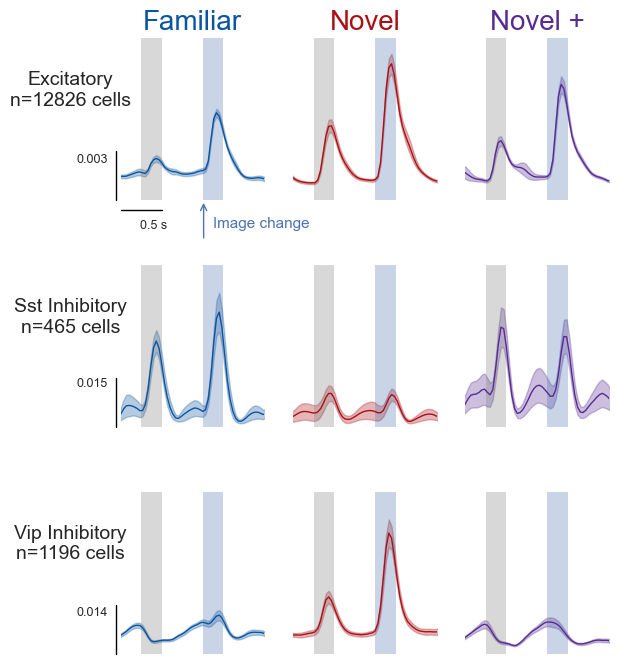

In [11]:
df = change_mdf.copy()
xlim_seconds = [-1., 0.75]

ppf.plot_population_averages_for_cell_types_across_experience(
    df, xlim_seconds=xlim_seconds, xlabel='Time from image change (s)',
    ylabel='Calcium events', data_type=data_type, event_type='changes',
    interval_sec=1, save_dir=save_dir, folder='population_activity',
    suffix='_changes_stacked', ax=None)

#### Quantification of mean response

array([<Axes: ylabel='Excitatory'>,
       <Axes: ylabel='Mean non-change image response\n\nSst Inhibitory'>,
       <Axes: ylabel='Vip Inhibitory'>], dtype=object)

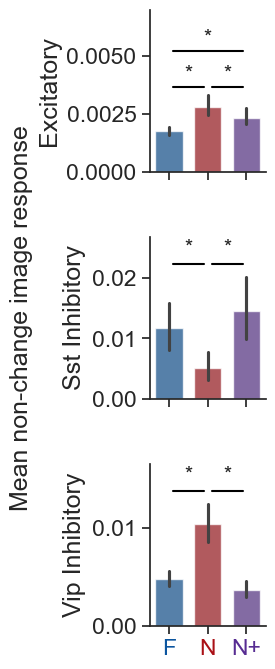

In [12]:
metric = 'mean_response_all_images'
ylabel = 'Mean non-change image response'

event_type = 'all'

ppf.plot_metric_distribution_by_experience(metrics_table, metric, plot_type='barplot', #show_containers=True,
                                           horiz=False, add_zero_line=False, event_type=event_type, data_type=data_type,
                                           ylabel=ylabel, ylims=None, save_dir=save_dir, ax=None)



array([<Axes: ylabel='Excitatory'>,
       <Axes: ylabel='Mean image change response\n\nSst Inhibitory'>,
       <Axes: ylabel='Vip Inhibitory'>], dtype=object)

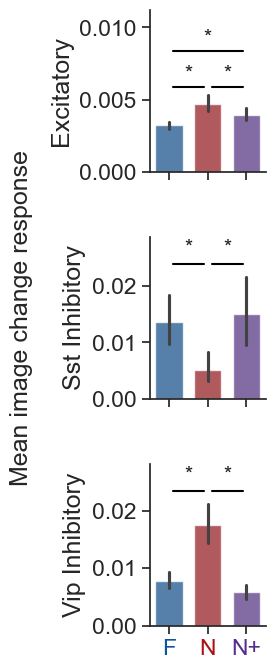

In [13]:
metric = 'mean_response_changes'
ylabel = 'Mean image change response'

event_type = 'changes'

ppf.plot_metric_distribution_by_experience(metrics_table, metric, plot_type='barplot', 
                                           horiz=False, add_zero_line=False, event_type=event_type, data_type=data_type,
                                           ylabel=ylabel, ylims=None, save_dir=save_dir, ax=None)



array([<Axes: ylabel='Excitatory'>,
       <Axes: ylabel='Mean non-change image response - pref image\n\nSst Inhibitory'>,
       <Axes: ylabel='Vip Inhibitory'>], dtype=object)

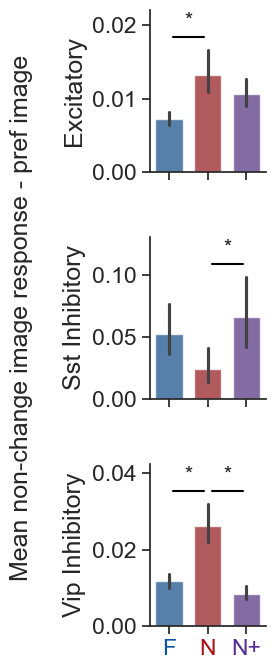

In [14]:
metric = 'mean_response_pref_image'
ylabel = 'Mean non-change image response - pref image'
event_type = 'pref_image'

ppf.plot_metric_distribution_by_experience(metrics_table, metric, plot_type='barplot', #show_containers=True,
                                           horiz=False, add_zero_line=False, event_type=event_type, data_type=data_type,
                                           ylabel=ylabel, ylims=None, save_dir=save_dir, ax=None)



#### Percent responsive cells

Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='% Non-change image responsive cells'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

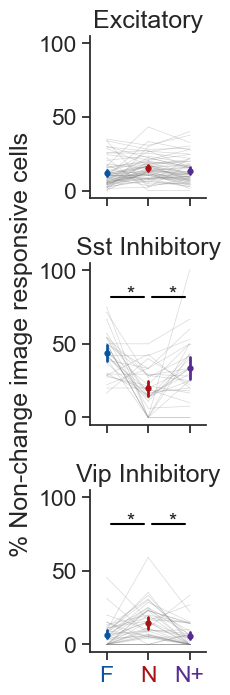

In [15]:
# Quantify fraction of cells responsive to their preferred stimulus
df = each_image_mdf[(each_image_mdf.is_change==False)& (each_image_mdf.pref_stim==True)]

ppf.plot_percent_responsive_cells(df, responsiveness_threshold=0.2, ylim=(-5, 105), ylabel='% Non-change image responsive cells',
                                    save_dir=save_dir, folder =folder, suffix='_images_pref_stim', horizontal=False, ax=None, event_type='images')


Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='% Image change responsive cells'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

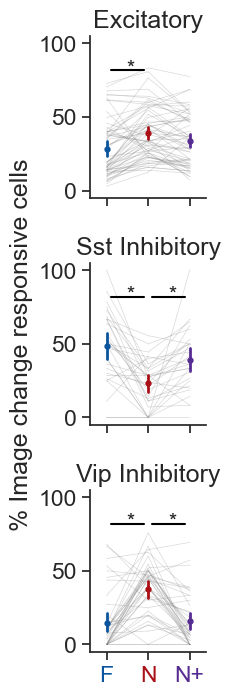

In [16]:
# Quantify fraction of cells responsive to their preferred stimulus
df = each_image_mdf[(each_image_mdf.is_change==True)& (each_image_mdf.pref_stim==True)]

ppf.plot_percent_responsive_cells(df, responsiveness_threshold=0.2, ylim=(-5, 105), ylabel='% Image change responsive cells',
                                    save_dir=save_dir, folder =folder, suffix='_changes_pref_stim', horizontal=False, ax=None, event_type='changes')


#### Change modulation

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y

array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='Change modulation'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

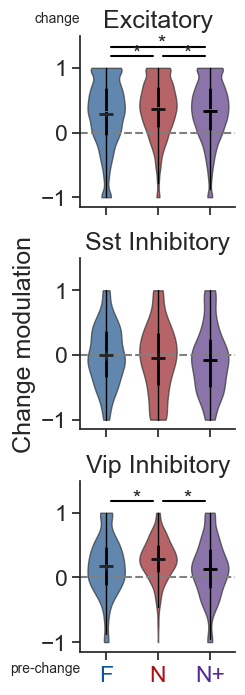

In [17]:
metric = 'change_modulation_index'
xlabel = 'Change modulation'
event_type = 'changes'
annot = ('pre-change', 'change')
xlims = (-1.15, 1.15)

ppf.plot_modulation_index_distribution(metrics_table, metric, label=xlabel, 
                                       lims=xlims, horiz=False, annot=annot, metric_on_y=True,
                                        abbreviate_exp=True, suptitle=None, fill=True, 
                                        save_dir=save_dir, event_type='changes')


In [18]:
missing_ids = metrics_table.loc[
    ~metrics_table['ophys_experiment_id'].isin(change_mdf['ophys_experiment_id']),
    'ophys_experiment_id'].unique()

tmp = metrics_table[metrics_table.ophys_experiment_id.isin(missing_ids)==False]

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y

array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='Change modulation'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

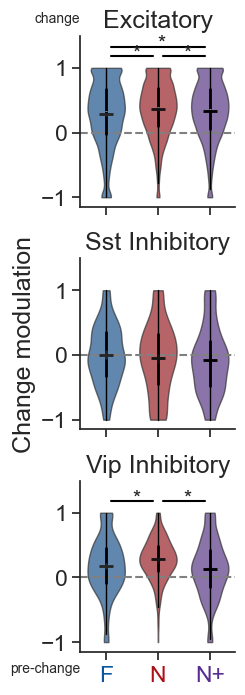

In [19]:
metric = 'change_modulation_index'
xlabel = 'Change modulation'
event_type = 'changes'
annot = ('pre-change', 'change')
xlims = (-1.15, 1.15)

ppf.plot_modulation_index_distribution(tmp, metric, label=xlabel, 
                                       lims=xlims, horiz=False, annot=annot, metric_on_y=True,
                                        abbreviate_exp=True, suptitle=None, fill=True, 
                                        save_dir=save_dir, event_type='changes')


In [20]:
print('image_mdf.mouse_id dtype:', image_mdf.mouse_id.dtype)
print('platform_cells_table.mouse_id dtype:', platform_cells_table.mouse_id.dtype)

image_mdf.mouse_id dtype: int64
platform_cells_table.mouse_id dtype: int64


#### Experience modulation

Quantification of how neural responses change across experience levels. Includes
experience modulation index (computed as the difference in mean response between
two experience levels divided by the sum) for each cell, shown as distributions
per cell type. Also shows mean image change response magnitude across cohorts,
depths, and cortical areas, and the change modulation index (response to image
changes minus response to non-change images, over the sum) split by area and
depth. Corresponds to PPT Figure S6 panels I-N.

In [21]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}>,
       <Axes: title={'center': 'Vip Inhibitory'}, xlabel='Experience modulation'>],
      dtype=object)

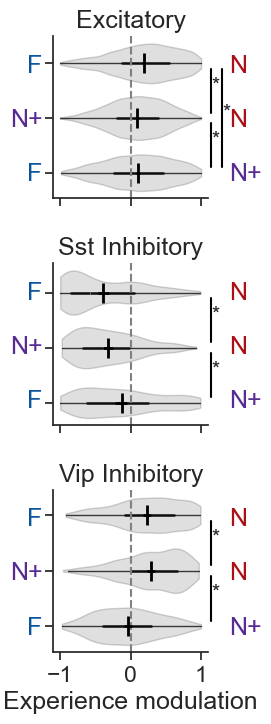

In [22]:
metric = 'mean_response'
event_type = 'images'
xlabel = 'Experience modulation'

ppf.plot_experience_modulation_index_annotated_by_cell_type(image_mdf, event_type, metric, platform_cells_table,
                                                            xlims=(-1.1, 1.1), xlabel=xlabel,
                                                            all_comparisons=True, horiz=False,
                                                            suptitle=None, suffix='', save_dir=None, ax=None)

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:4373: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_yticklabels([cell_type[:3] for cell_type in cell_types])
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:4373: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_yticklabels([cell_type[:3] for cell_type in cell_types])
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:4373: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_yticklabels([cell_type[:3] for cell_type in cell_types])


array([<Axes: title={'center': 'Novel vs. Familiar'}>,
       <Axes: title={'center': 'Novel vs. Novel +'}>,
       <Axes: title={'center': 'Novel + vs. Familiar'}, xlabel='Experience modulation'>],
      dtype=object)

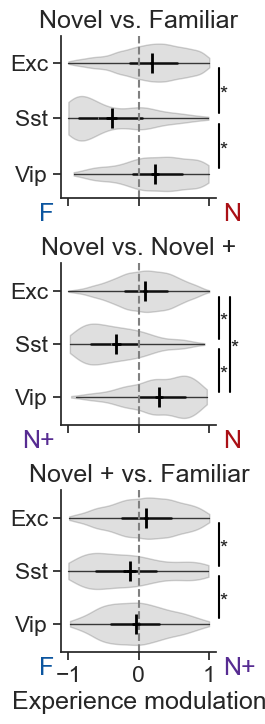

In [23]:
metric = 'mean_response'
event_type = 'images'
xlabel = 'Experience modulation'

ppf.plot_experience_modulation_index_annotated(
    image_mdf, event_type, metric, platform_cells_table,
    horiz=False, xlims=(-1.1, 1.1), xlabel='Experience modulation',
    suffix='_images_modulation', save_dir=save_dir,)

##### Experience vs change modulation 

### Population activity for image omissions

#### Population mean response

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

removing 1 problematic experiments


array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nn=12826 cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nn=465 cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nn=1197 cells'>, <Axes: >, <Axes: >],
      dtype=object)

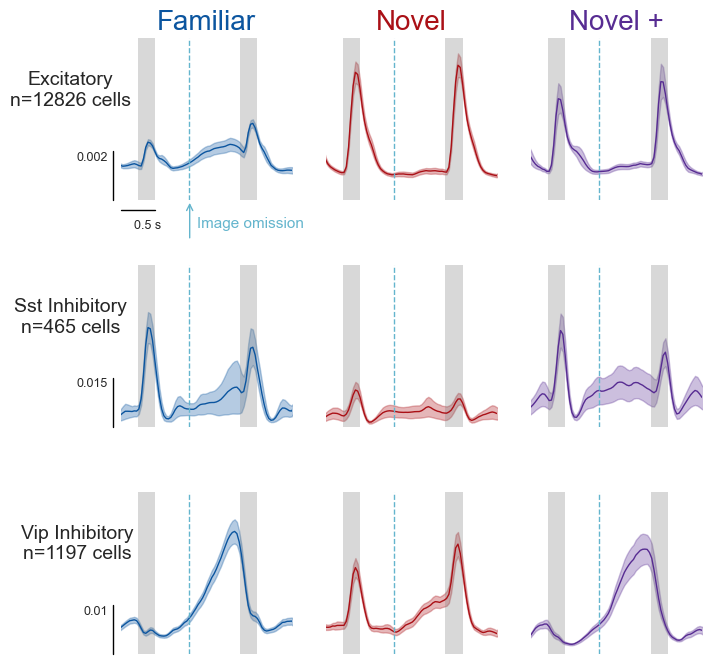

In [24]:
df = omission_mdf.copy()
xlim_seconds = [-1., 1.5]

ppf.plot_population_averages_for_cell_types_across_experience(
    df, xlim_seconds=xlim_seconds, xlabel='Time from image omission (s)',
    ylabel='Calcium events', data_type=data_type, event_type='omissions',
    interval_sec=1, save_dir=save_dir, folder='population_activity',
    suffix='', ax=None)

### Quantification of mean response

array([<Axes: ylabel='Excitatory'>,
       <Axes: ylabel='Mean image omission response\n\nSst Inhibitory'>,
       <Axes: ylabel='Vip Inhibitory'>], dtype=object)

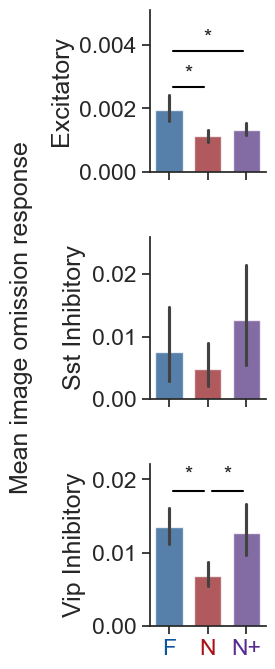

In [25]:
metric = 'mean_response_omissions'
ylabel = 'Mean image omission response'
event_type = 'omissions'

ppf.plot_metric_distribution_by_experience(
    metrics_table, metric, plot_type='barplot', horiz=False,
    suptitle='', add_zero_line=False, event_type=event_type, data_type=data_type,
    ylabel=ylabel, ylims=None, save_dir=save_dir, ax=None)

#### Percent responsive cells 

Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='% Image omission responsive cells'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

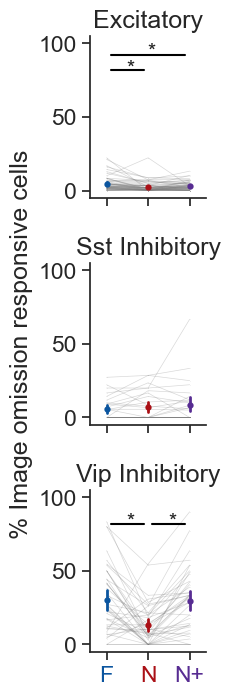

In [26]:
# Quantify fraction of cells responsive to their preferred stimulus
df = omission_mdf.copy()

ppf.plot_percent_responsive_cells(df, responsiveness_threshold=0.1, ylim=(-5, 105), 
                                    ylabel='% Image omission responsive cells',
                                    save_dir=save_dir, folder =folder, suffix='_omissions_pref_stim', 
                                    horizontal=False, ax=None, event_type='omissions')


### Single cell diversity

Example container and cells for matched cell plotting

#### Matched cell response heatmaps

##### Image changes

Sst Inhibitory: dropping 8 of 198 matched cells not present in all 3 experience_level conditions
Vip Inhibitory: dropping 10 of 411 matched cells not present in all 3 experience_level conditions


array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nmatched cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nmatched cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nmatched cells'>,
       <Axes: xlabel='Time from image onset (s)'>, <Axes: >], dtype=object)

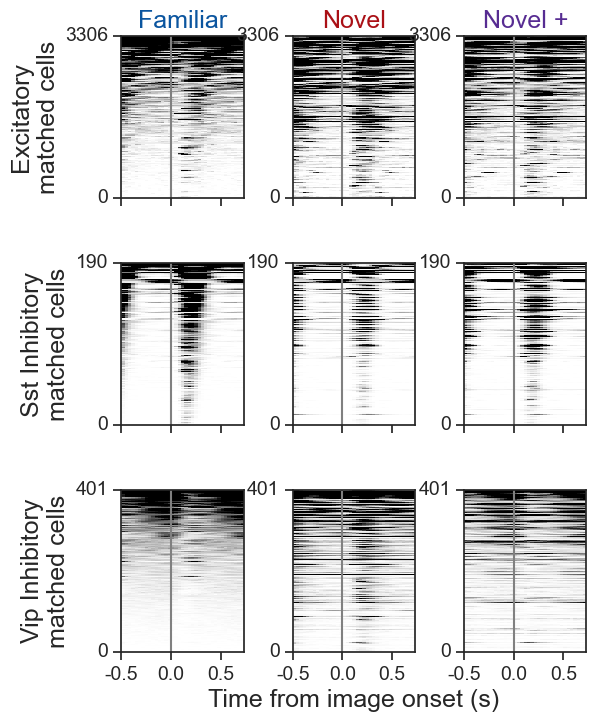

In [27]:
df = image_mdf.copy()

xlim_seconds = [-0.5, 0.75]

event_type = 'images'

timestamps = df.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'

ppf.plot_response_heatmaps_for_conditions(df, timestamps, data_type, event_type, row_condition, col_condition, 
                                          col_to_sort_by='mean_baseline', suptitle='', xlabel='Time from image onset (s)',
                                          match_cells=True, matched_cells_table=matched_cells_table,
                                          exp_to_match='Familiar', xlim_seconds=xlim_seconds, cbar=False,
                                          save_dir=save_dir, suffix='', ax=None)



array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nmatched cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nmatched cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nmatched cells'>,
       <Axes: xlabel='Time from image change (s)'>, <Axes: >],
      dtype=object)

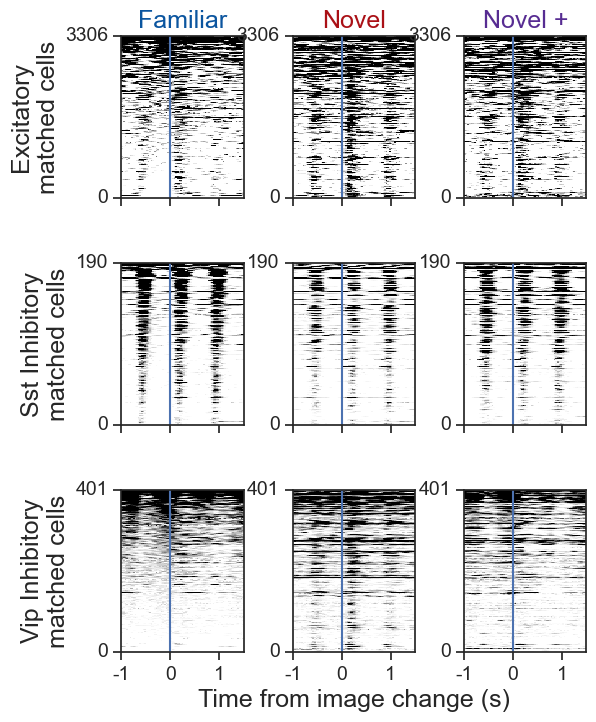

In [28]:
# Cell-matched response heatmaps for images
timestamps = change_mdf.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'
cols_to_sort_by = ['mean_response']

# Cell-matched population averages for changes
matched_changes = utilities.limit_to_cell_specimen_ids_matched_in_all_experience_levels(change_mdf)
xlim_seconds = [-1., 1.5]

# Cell-matched response heatmaps for changes
ppf.plot_response_heatmaps_for_conditions(
    matched_changes, timestamps, data_type, 'changes', row_condition, col_condition,
    col_to_sort_by='mean_baseline', suptitle='Matched cells - Changes',
    xlabel='Time from image change (s)', exp_to_match='Familiar', matched_cells_table=matched_cells_table,
    microscope=None, xlim_seconds=[-1, 1.5], match_cells=True, cbar=False,
    save_dir=save_dir, suffix='_matched_changes', ax=None)

##### Image omissions

array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\ncells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\ncells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\ncells'>,
       <Axes: xlabel='Time from image omission (s)'>, <Axes: >],
      dtype=object)

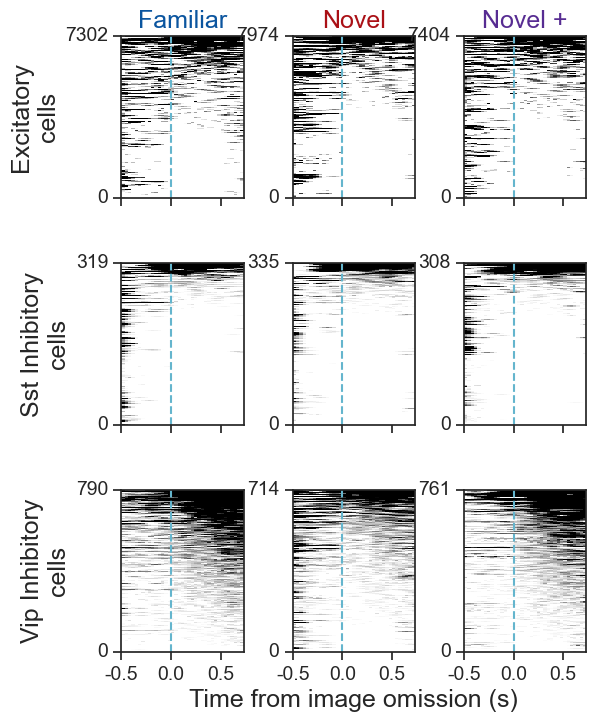

In [29]:
df = omission_mdf.copy()

xlim_seconds = [-0.5, 0.75]

event_type = 'omissions'

timestamps = df.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'

ppf.plot_response_heatmaps_for_conditions(df, timestamps, data_type, event_type, row_condition, col_condition, 
                                          col_to_sort_by='mean_response', suptitle='', xlabel='Time from image omission (s)',
                                          microscope=None, vmax=None, xlim_seconds=xlim_seconds, match_cells=False, cbar=False,
                                          save_dir=None, suffix='_heatmap_omissions', ax=None)

array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nmatched cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nmatched cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nmatched cells'>,
       <Axes: xlabel='Time from omission (s)'>, <Axes: >], dtype=object)

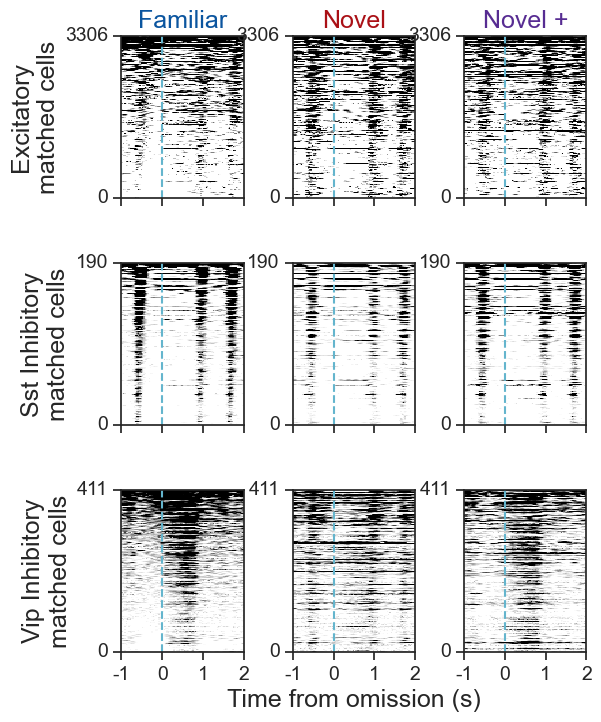

In [30]:
# Population averages for omissions - heatmaps
timestamps = omission_mdf.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'

# Cell-matched omission heatmaps
matched_omissions = utilities.limit_to_cell_specimen_ids_matched_in_all_experience_levels(omission_mdf)

ppf.plot_response_heatmaps_for_conditions(
    matched_omissions, timestamps, data_type, 'omissions', row_condition, col_condition,
    col_to_sort_by='mean_baseline', suptitle='Matched cells - Omissions',
    xlabel='Time from omission (s)', exp_to_match='Familiar', matched_cells_table=matched_cells_table,
    microscope=None, xlim_seconds=[-1, 2], match_cells=True, cbar=False,
    save_dir=save_dir, suffix='_matched_omissions', ax=None)

#### Matched cell example responses across sessions 

In [31]:
Vip_containers = [1018027599, 1018027859, 1046576787, 1018027862, 1018028367]

Sst_containers = [1018028339, 1018028135, 1018028202, 1018028153, 1074913336]

Exc_containers = [1018027663, 1018027790, 1018028046, 1074922997, 1079028117, 1018027775,]


##### Image changes

In [32]:
%load_ext autoreload
%autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


###### Excitatory

In [33]:
# Exc_change_cells = [1086579153, 1086559786, 1086523675,  1086514966, 1086514622, 1120104688,  #1086514606, ]
#                      1086558573, 1086527750, 1086517398, 1086577182, 1120108338, 1086510825, ]#1086558285, 1086519596, 1086529704, ]

# event_type = 'images'
# cell_type = 'Excitatory'

# df = each_image_mdf[(each_image_mdf.pref_stim==True) & (each_image_mdf.is_change==False)].copy()

# pse.plot_reliable_example_cells(df, Exc_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-0.25, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_images_selected')


In [34]:
# Exc_change_cells = [1086579153, 1086559786, 1086523675,  1086514966, 1086514622, 1120104688,  #1086514606, ]
#                      1086558573, 1086527750, 1086517398, 1086577182, 1120108338, 1086510825, ]#1086558285, 1086519596, 1086529704, ]

# event_type = 'changes'

# cell_type = 'Excitatory'
# pse.plot_reliable_example_cells(change_mdf, Exc_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-0.25, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


In [35]:
# Exc_change_cells = [1086579153, 1086559786, 1086523675,  1086514966, 1086514622, 1120104688,  1086514606, 
#                      1086558573, 1086527750, 1086517398, 1086577182, 1120108338, 1086510825, 1086558285, 1086519596, 1086529704, ]

# event_type = 'changes'

# cell_type = 'Excitatory'
# pse.plot_reliable_example_cells(change_mdf, Exc_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-1, 1.5],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


In [36]:
%load_ext autoreload
%autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


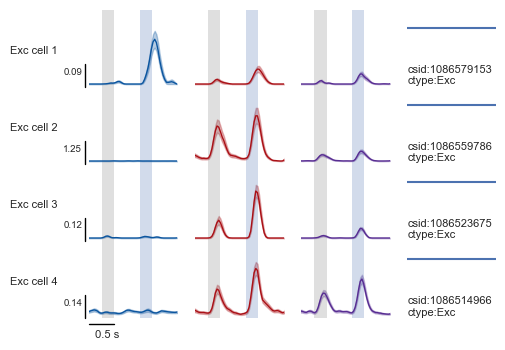

In [37]:
Exc_change_cells = [1086579153, 1086559786, 1086523675,  1086514966, 1086514622, 1120104688,  #1086514606, ]
                     1086558573, 1086527750, 1086517398, 1086577182, 1120108338, 1086510825, ]#1086558285, 1086519596, 1086529704, ]

event_type = 'changes'

pse.plot_selected_cell_examples(change_mdf, Exc_change_cells[:4], event_type=event_type,
                                xlim_seconds=[-1, 0.75], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_Exc_changes')
    


In [38]:
Exc_change_cells = matched_cells_table[(matched_cells_table.cell_type=='Excitatory') & 
                                        (matched_cells_table.project_code=='VisualBehavior') &
                                        (matched_cells_table.binned_depth==175)].cell_specimen_id.unique()
Exc_change_cells = np.random.choice(Exc_change_cells, 10)

In [39]:
# for cell_specimen_id in Exc_change_cells:
#     pse.plot_matched_roi_mask_zoom(cell_specimen_id, platform_cells_table, platform_experiments, save_dir=save_dir)


###### Sst Inhibitory

In [40]:
# Sst_change_cells =  [1086579643, 1120094089, 1086575280, 1086551540, 1086581760, 1086572621, ]
#                     # 1086559885, 1086619787, 1086553602, 1120094297]
# #1086575742, ]
# cell_type = 'Sst Inhibitory'
# event_type = 'images'
# df = each_image_mdf[(each_image_mdf.pref_stim==True) & (each_image_mdf.is_change==False)].copy()

# pse.plot_reliable_example_cells(df, Sst_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-0.25, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


In [41]:
# Sst_change_cells =  [1086579643, 1120094089, 1086575280, 1086551540, 1086581760, 1086572621, ]
#                     # 1086559885, 1086619787, 1086553602, 1120094297]
# #1086575742, ]
# cell_type = 'Sst Inhibitory'
# event_type = 'changes'

# pse.plot_reliable_example_cells(change_mdf, Sst_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-0.25, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


In [42]:
# Sst_change_cells =  [1086579643, 1120094089, 1086575280, 1086551540, 1086581760, 1086572621, ]
#                     # 1086559885, 1086619787, 1086553602, 1120094297]
# #1086575742, ]
# cell_type = 'Sst Inhibitory'
# event_type = 'changes'

# pse.plot_reliable_example_cells(change_mdf, Sst_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-1, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')

In [43]:
# Sst_change_cells =  [1086579643, 1120094089, 1086575280, 1086551540, 1086581760, 1086572621, ]
#                     # 1086559885, 1086619787, 1086553602, 1120094297]
# #1086575742, ]
# cell_type = 'Sst Inhibitory'
# event_type = 'changes'

# pse.plot_reliable_example_cells(change_mdf, Sst_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-1, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


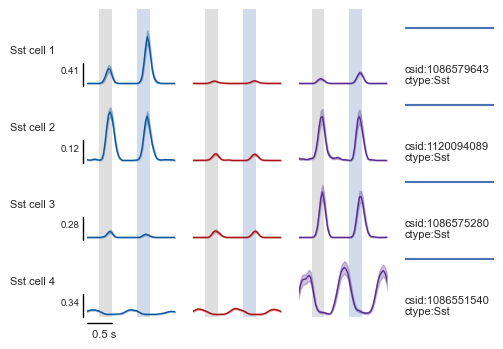

In [44]:
Sst_change_cells =  [1086579643, 1120094089, 1086575280, 1086551540, 1086581760, 1086572621, ]

cell_type = 'Sst Inhibitory'
event_type = 'changes'

pse.plot_selected_cell_examples(change_mdf, Sst_change_cells[:4], event_type=event_type,
                                xlim_seconds=[-1, 0.75], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_Sst_changes')
    

In [45]:
    
# for cell_specimen_id in Sst_change_cells[:4]:
#     pse.plot_matched_roi_mask_zoom(cell_specimen_id, platform_cells_table, platform_experiments, save_dir=save_dir)


###### Vip Inhibitory

In [46]:
# Vip_change_cells = [1086673402, 1086501825, 1086627590, 1086514444, 1086627527, 1086514260, ] 

# itory'
# event_type = 'images'
# df = each_image_mdf[(each_image_mdf.pref_stim==True) & (each_image_mdf.is_change==False)].copy()

# pse.plot_reliable_example_cells(df, Vip_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-0.25, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


In [47]:

# Vip_change_cells = [1086673402, 1086501825, 1086627590, 1086514444, 1086627527, 1086514260, ] 
# # 1086627395, 1086673073, 1086519532, 1086516885, 1086615418, ]
# event_type='changes'
# cell_type = 'Vip Inhibitory'
# pse.plot_reliable_example_cells(change_mdf, Vip_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-0.25, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


In [48]:
# event_type='changes'
# cell_type = 'Vip Inhibitory'
# pse.plot_reliable_example_cells(change_mdf, Vip_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-1, 1.5],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


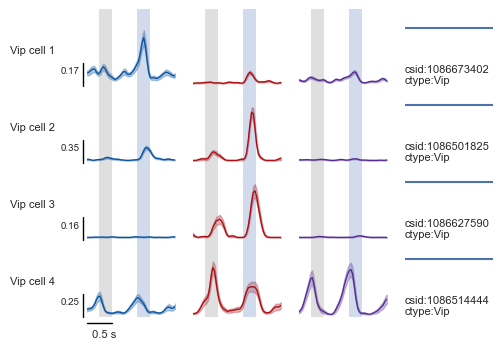

In [49]:
Vip_change_cells = [1086673402, 1086501825, 1086627590, 1086514444, 1086627527, 1086514260, ] 

event_type = 'changes'

pse.plot_selected_cell_examples(change_mdf, Vip_change_cells[:4], event_type=event_type,
                                xlim_seconds=[-1, 0.75], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_Vip_changes')
    


In [50]:
# for cell_specimen_id in Vip_change_cells[4:]:
#     pse.plot_matched_roi_mask_zoom(cell_specimen_id, platform_cells_table, platform_experiments, save_dir=save_dir)


##### Image omissions

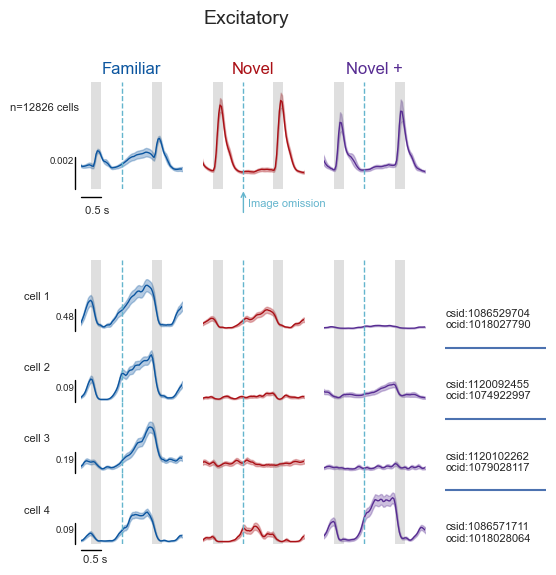

In [51]:
Exc_omission_cells = [ 1086529704, 1120092455, 1120102262, 1086571711,  1086514606, 
                      1086530117, 1120090879,  1086526518,]
event_type = 'omissions'

cell_type = 'Excitatory'
pse.plot_reliable_example_cells(omission_mdf, Exc_omission_cells[:4], cell_type, event_type=event_type, 
                                xlim_seconds=[-1, 1.5],
                                save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')

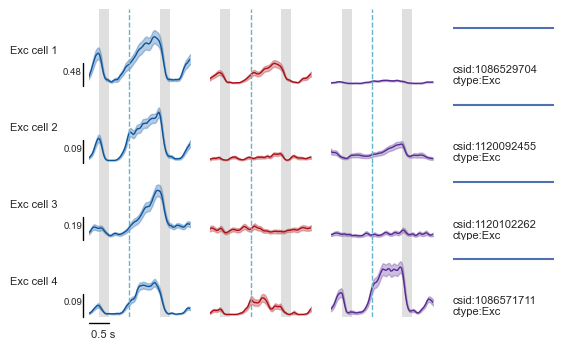

In [52]:
Exc_omission_cells = [ 1086529704, 1120092455, 1120102262, 1086571711,  1086514606, 
                      1086530117, 1120090879,  1086526518,]
event_type = 'omissions'

pse.plot_selected_cell_examples(omission_mdf, Exc_omission_cells[:4], event_type=event_type,
                                xlim_seconds=[-1, 1.5], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_Exc_omissions')
    


24


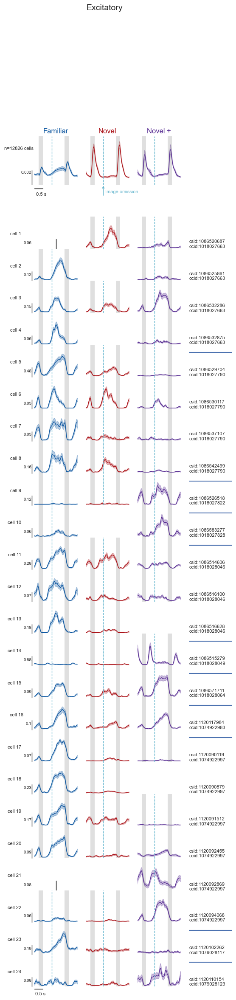

In [53]:
cell_types = utils.get_cell_types()
cell_type = 'Excitatory'
# for cell_type in cell_types: 
event_type = 'omissions'
# get reliable cells for this cell type
reliable_cells = omission_mdf[(omission_mdf.fraction_significant_p_value_gray_screen>0.15) & 
            (omission_mdf.mean_response > 0.1) &
            (omission_mdf.cell_type==cell_type)]
reliable_cells = reliable_cells.sort_values(by=['ophys_container_id', 'cell_specimen_id'])
cells_to_plot = reliable_cells.cell_specimen_id.unique()
print(len(cells_to_plot))

pse.plot_reliable_example_cells(omission_mdf, cells_to_plot, cell_type, event_type=event_type, 
                                save_dir=save_dir, folder='reliable_example_cells', suffix='_top_cells')

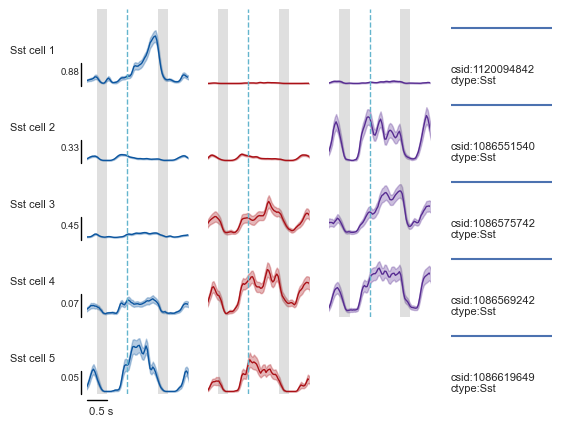

In [54]:
Sst_omission_cells = [1120094842, 1086551540, 1086575742, 1086569242, 
                       1086619649,]

event_type = 'omissions'

pse.plot_selected_cell_examples(omission_mdf, Sst_omission_cells, event_type=event_type,
                                xlim_seconds=[-1, 1.5], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_Sst_omissions')
    


12


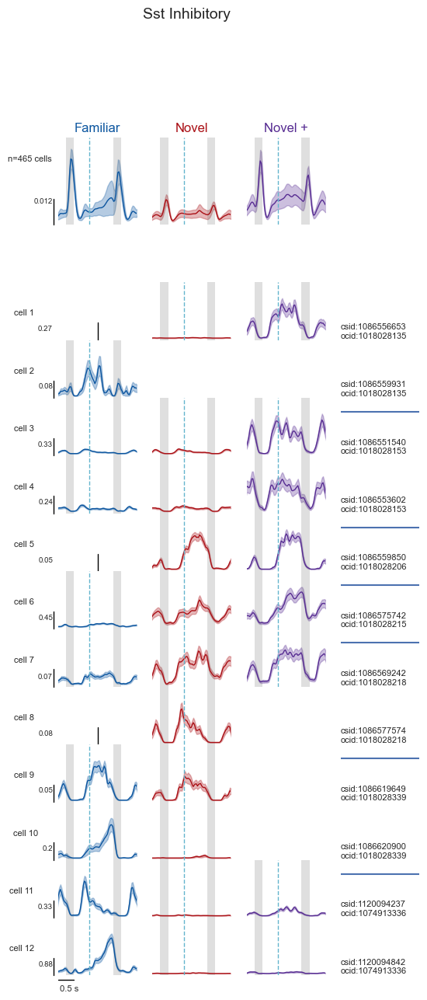

In [55]:
cell_types = utils.get_cell_types()
cell_type = 'Sst Inhibitory'
# for cell_type in cell_types: 
event_type = 'omissions'
# get reliable cells for this cell type
reliable_cells = omission_mdf[(omission_mdf.fraction_significant_p_value_gray_screen>0.15) & 
            (omission_mdf.mean_response > 0.1) &
            (omission_mdf.cell_type==cell_type)]
reliable_cells = reliable_cells.sort_values(by=['ophys_container_id', 'cell_specimen_id'])
cells_to_plot = reliable_cells.cell_specimen_id.unique()
print(len(cells_to_plot))

pse.plot_reliable_example_cells(omission_mdf, cells_to_plot, cell_type, event_type=event_type, 
                                save_dir=save_dir, folder='reliable_example_cells', suffix='_top_cells')

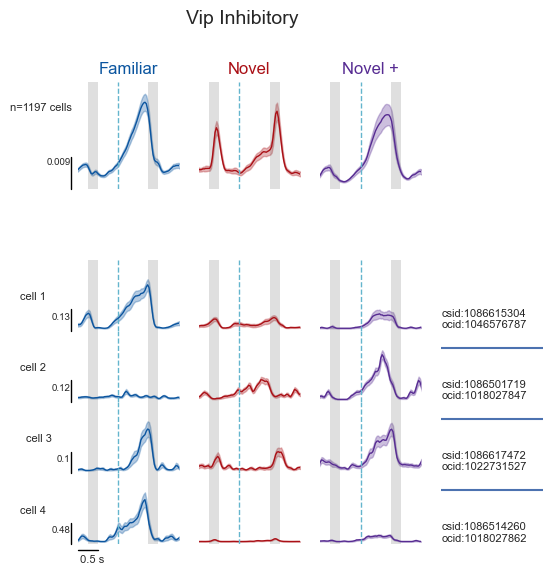

In [56]:
Vip_omission_cells = [1086615304, 1086501719, 1086617472, 1086514260, 1086616294, 1086514444, 
                      1086614936 ,1086614349, 1086510096, 1086673225,  1086516885, 1086627910,  ]
                      
event_type = 'omissions'

cell_type = 'Vip Inhibitory'
pse.plot_reliable_example_cells(omission_mdf, Vip_omission_cells[:4], cell_type, event_type=event_type, 
                                xlim_seconds=[-1, 1.5],
                                save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


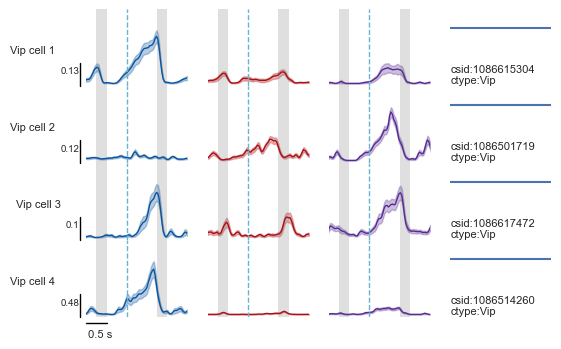

In [57]:
Vip_omission_cells = [1086615304, 1086501719, 1086617472, 1086514260, 1086616294, 1086514444, 
                      1086614936 ,1086614349, 1086510096, 1086673225,  1086516885, 1086627910,  ]
                      
event_type = 'omissions'


pse.plot_selected_cell_examples(omission_mdf, Vip_omission_cells[:4], event_type=event_type,
                                xlim_seconds=[-1, 1.5], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_Vip_omissions')
    


56


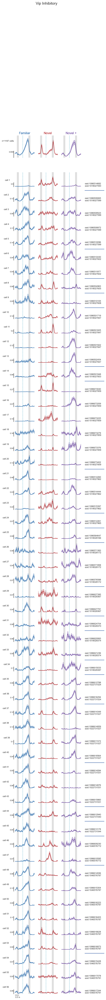

In [58]:
cell_types = utils.get_cell_types()
cell_type = 'Vip Inhibitory'
# for cell_type in cell_types: 
event_type = 'omissions'
# get reliable cells for this cell type
reliable_cells = omission_mdf[(omission_mdf.fraction_significant_p_value_gray_screen>0.05) & 
            (omission_mdf.mean_response > 0.05) &
            (omission_mdf.cell_type==cell_type)]
reliable_cells = reliable_cells[reliable_cells.cell_specimen_id.isin(matched_cells)]
reliable_cells = reliable_cells.sort_values(by=['ophys_container_id', 'cell_specimen_id'])
cells_to_plot = reliable_cells.cell_specimen_id.unique()
print(len(cells_to_plot))

pse.plot_reliable_example_cells(omission_mdf, cells_to_plot, cell_type, event_type=event_type, 
                                save_dir=save_dir, folder='reliable_example_cells', suffix='_top_cells')

##### Omission examples sampled from the omission modulation index distribution

Excitatory enhanced: 83 candidate cells with fraction_significant_p_value_gray_screen > 0.15, plotting 20
Excitatory suppressed: 149 candidate cells with reliability > 0.1, plotting 10
Excitatory silent: 87 candidate cells with reliability > 0.1, plotting 10
Sst Inhibitory enhanced: 17 candidate cells with fraction_significant_p_value_gray_screen > 0.15, plotting 17
Sst Inhibitory suppressed: 8 candidate cells with reliability > 0.1, plotting 8
Sst Inhibitory silent: 386 candidate cells (no reliability criterion), plotting 10
Vip Inhibitory enhanced: 83 candidate cells with fraction_significant_p_value_gray_screen > 0.15, plotting 20
Vip Inhibitory suppressed: 22 candidate cells with reliability > 0.1, plotting 10
Vip Inhibitory silent: 9 candidate cells with reliability > 0.1, plotting 9


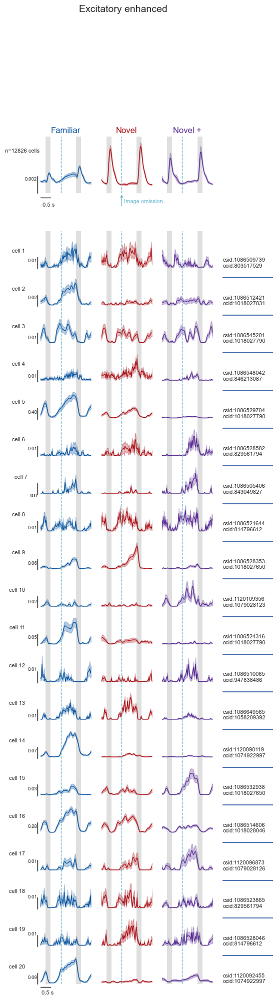

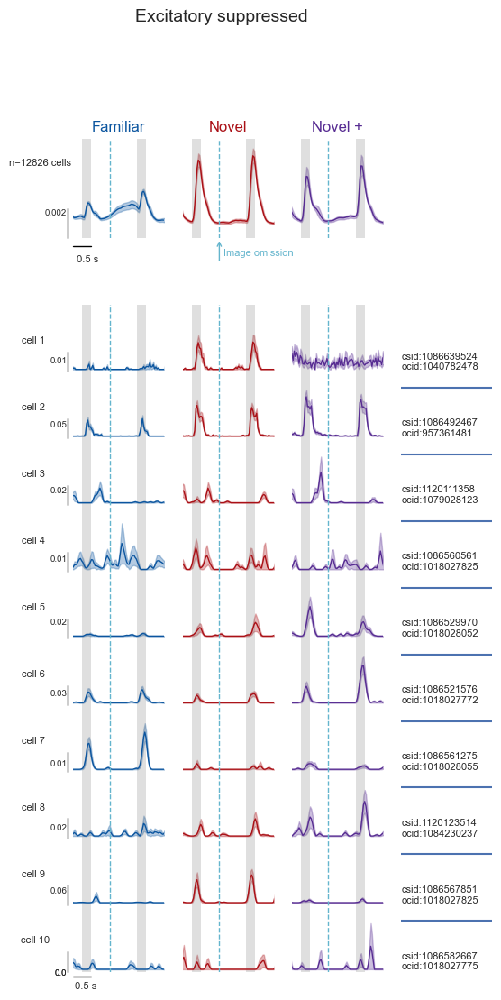

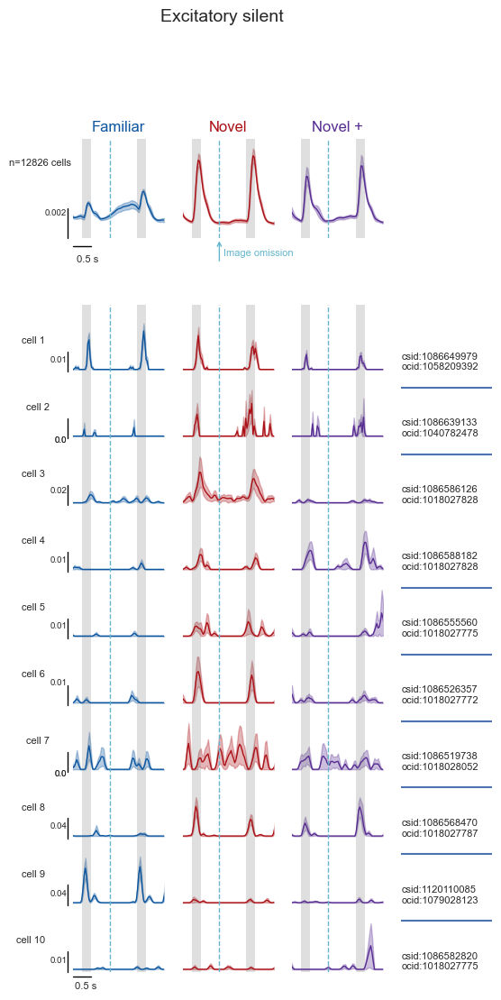

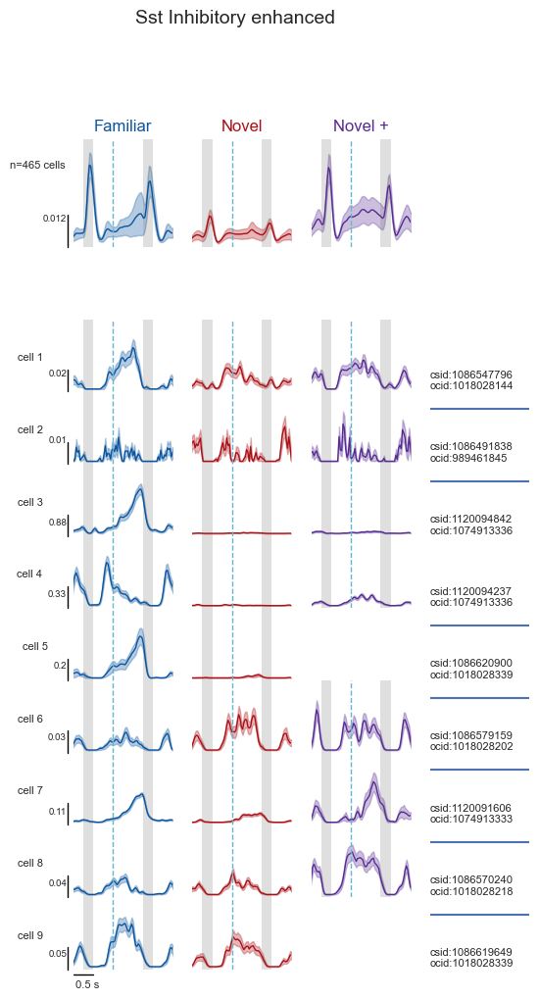

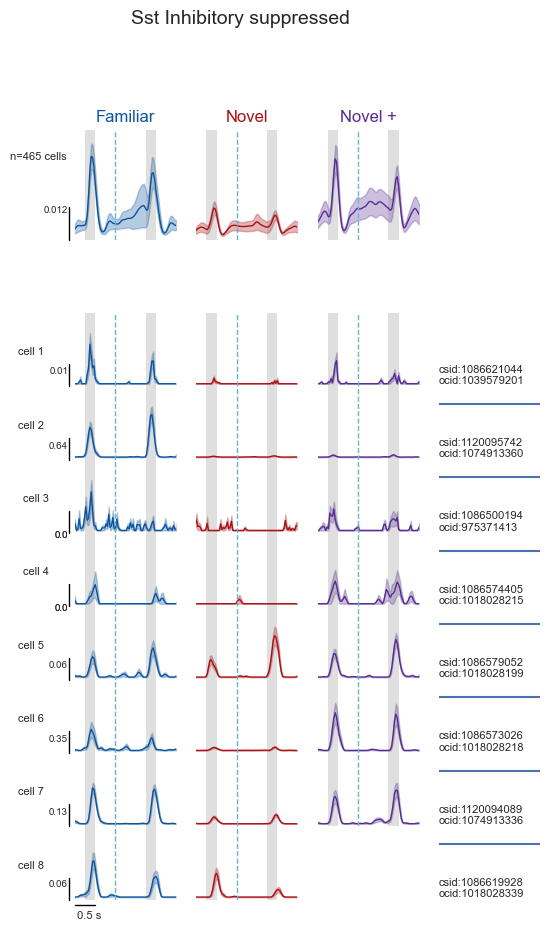

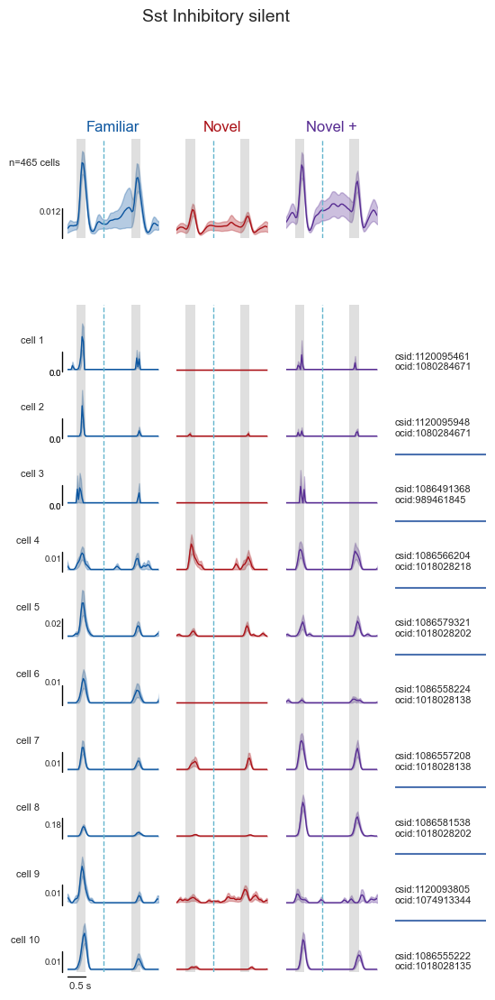

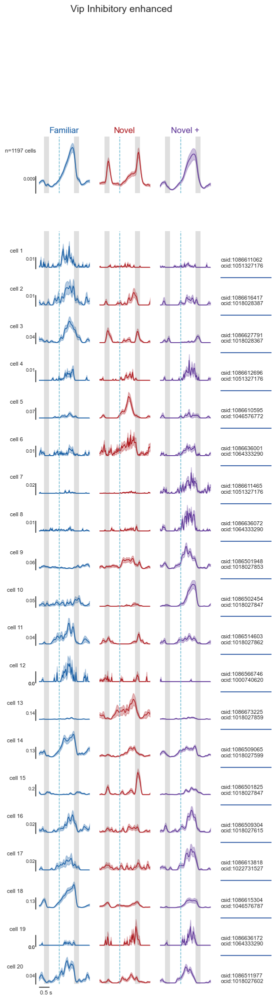

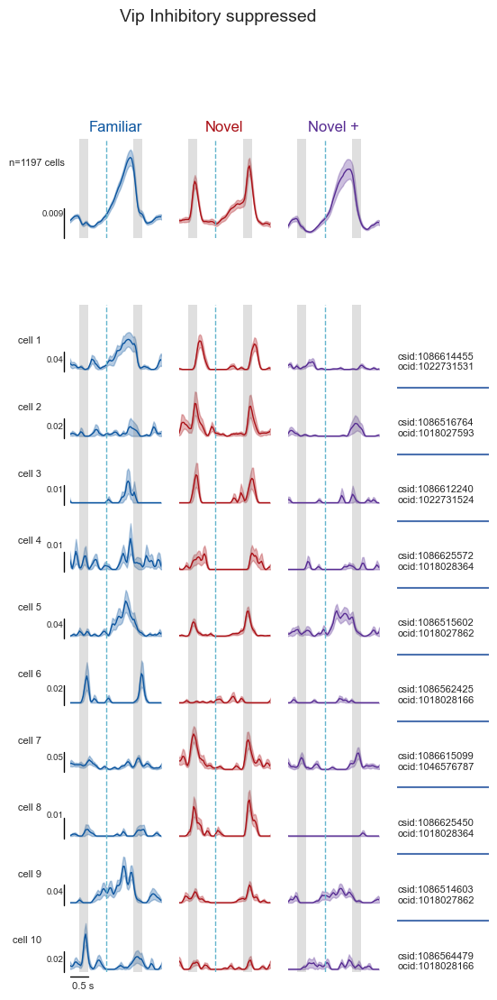

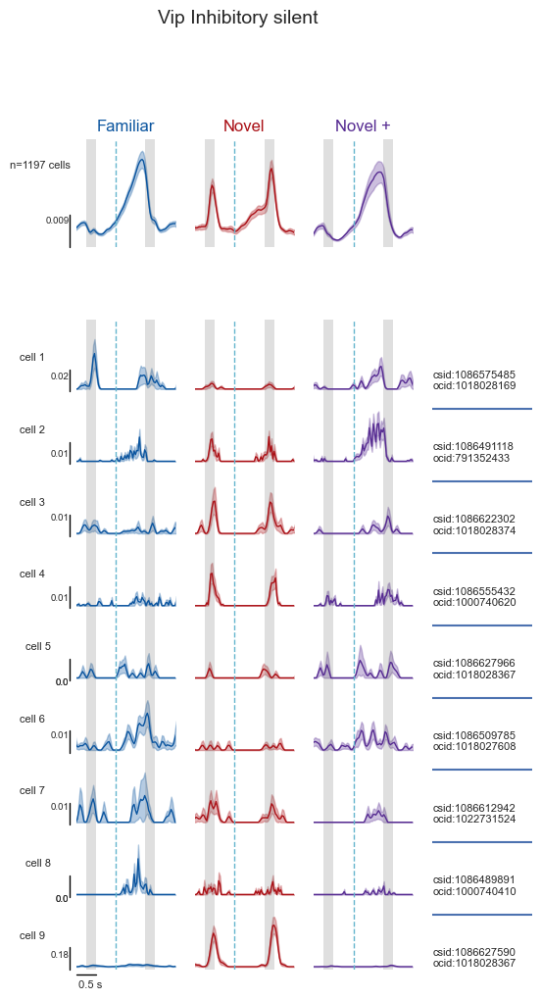

In [59]:
# Reviewer request (Fig 5H): pick omission example cells from the omission modulation index (OMI) distribution.
# For each cell type, pool cell-sessions across all experience levels and bin on the OMI value:
#   enhanced:   OMI > 0.5            filtered on fraction_significant_p_value_gray_screen > 0.1
#   suppressed: -1 < OMI < -0.5      filtered on reliability > 0.1 (excludes the pile-up at OMI = -1)
#   silent:     OMI = -1             filtered on reliability > 0.1 (no omission response at all)
# n_cells[bin] are drawn at random (fixed seed) from the candidates in each bin.
n_cells = {'enhanced': 20, 'suppressed': 10, 'silent': 10}
seed = 0
bin_filters = {'enhanced': ('fraction_significant_p_value_gray_screen', 0.15),
               'suppressed': ('reliability', 0.1),
               'silent': ('reliability', 0.1)}
event_type = 'omissions'

omi = metrics_table[['cell_specimen_id', 'ophys_experiment_id', 'omission_modulation_index']].drop_duplicates()
assert not omi.duplicated(['cell_specimen_id', 'ophys_experiment_id']).any()
omi_df = omission_mdf.merge(omi, on=['cell_specimen_id', 'ophys_experiment_id'], how='left')
omi_df = omi_df[omi_df.cell_specimen_id.isin(matched_cells)]

omi_example_cells = {}
for cell_type in utils.get_cell_types():
    ct_df = omi_df[(omi_df.cell_type == cell_type) & omi_df.omission_modulation_index.notnull()]
    omi_vals = ct_df.omission_modulation_index
    silent = np.isclose(omi_vals, -1)
    bin_masks = {'enhanced': omi_vals > 0.75,
                 'suppressed': (omi_vals < -0.75) & ~silent,
                 'silent': silent}
    for bin_name, in_omi_bin in bin_masks.items():
        filter_col, threshold = bin_filters[bin_name]
        in_bin = ct_df[in_omi_bin & (ct_df[filter_col] > threshold)]
        if len(in_bin)<5: # if there are no reliable cells in bin, drop the reliability criterion
            in_bin = ct_df[in_omi_bin]
            print(f'{cell_type} {bin_name}: {len(in_bin)} candidate cells (no {filter_col} criterion), '
                  f'plotting {min(n_cells[bin_name], len(in_bin))}')
        else: 
            print(f'{cell_type} {bin_name}: {len(in_bin)} candidate cells with {filter_col} > {threshold}, '
                  f'plotting {min(n_cells[bin_name], len(in_bin))}')        
        candidates = in_bin.cell_specimen_id.unique()
        rng = np.random.default_rng(seed)
        cells_to_plot = list(rng.choice(candidates, size=min(n_cells[bin_name], len(candidates)), replace=False))
        omi_example_cells[(cell_type, bin_name)] = cells_to_plot
        if len(cells_to_plot) == 0:
            continue
        pse.plot_reliable_example_cells(omission_mdf, cells_to_plot, cell_type, event_type=event_type,
                                        save_dir=save_dir, folder='reliable_example_cells',
                                        suptitle=f'{cell_type} {bin_name}', suffix=f'_omi_{bin_name}')

#### Top and bottom 5% examples

Excitatory bottom5: OMI [-1.00, -1.00], 89 candidate cells, plotting 10
Excitatory middle5: OMI [-0.87, -0.77], 81 candidate cells, plotting 10
Excitatory top5: OMI [0.82, 1.00], 89 candidate cells, plotting 20
Sst Inhibitory bottom5: OMI [-1.00, -1.00], 2 candidate cells, plotting 2
Sst Inhibitory middle5: OMI [-1.00, -1.00], 2 candidate cells, plotting 2
Sst Inhibitory top5: OMI [0.75, 1.00], 10 candidate cells, plotting 10
Vip Inhibitory bottom5: OMI [-1.00, -0.98], 14 candidate cells, plotting 10
Vip Inhibitory middle5: OMI [0.31, 0.43], 16 candidate cells, plotting 10
Vip Inhibitory top5: OMI [1.00, 1.00], 24 candidate cells, plotting 20


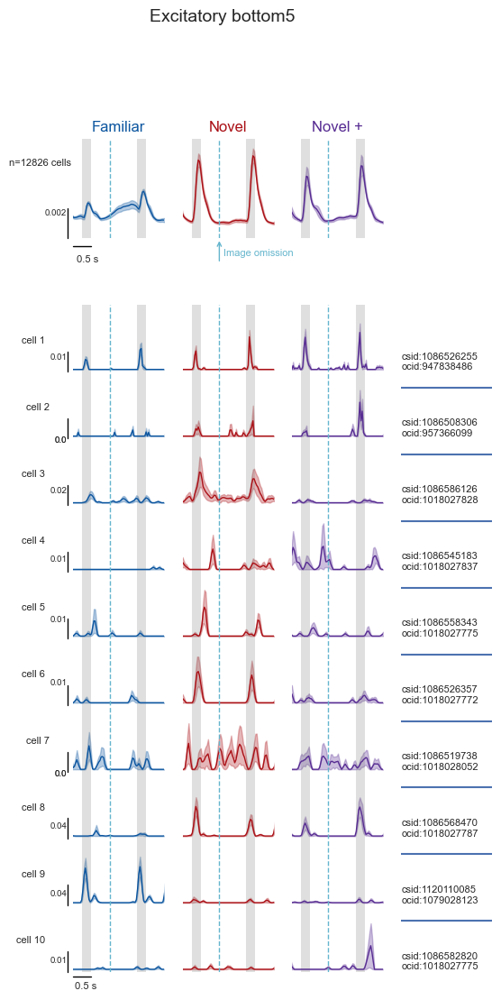

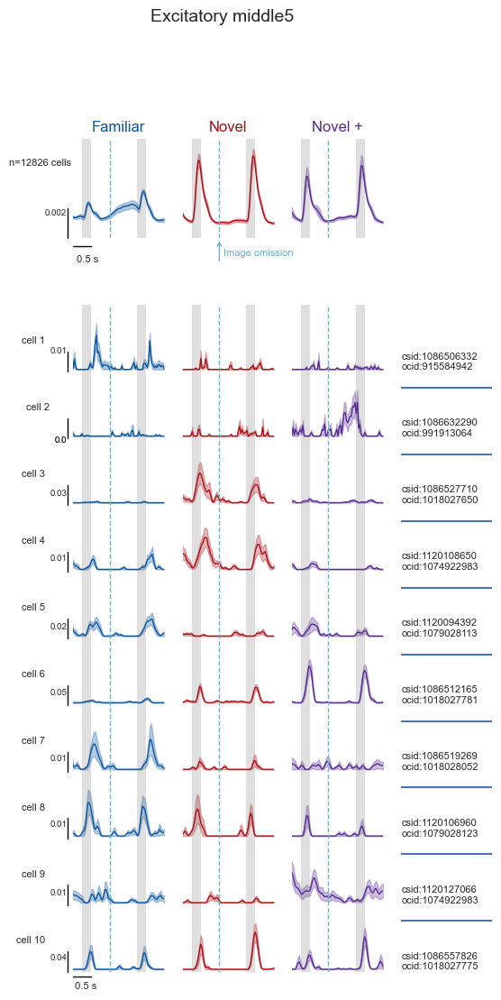

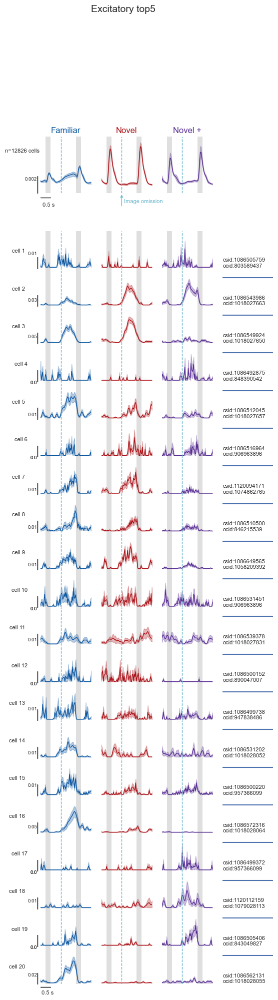

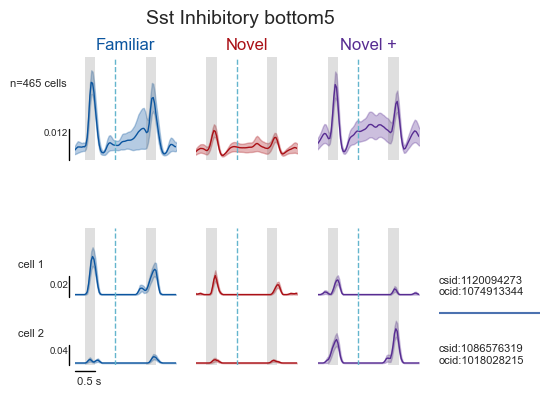

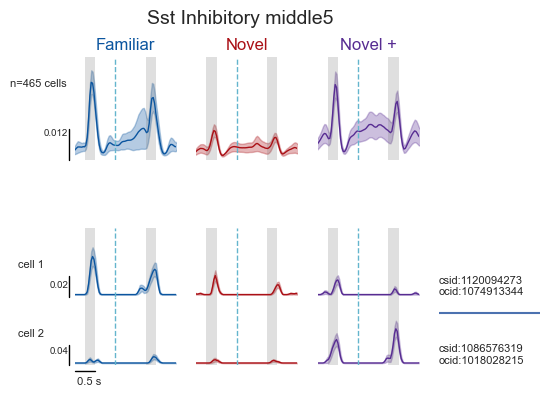

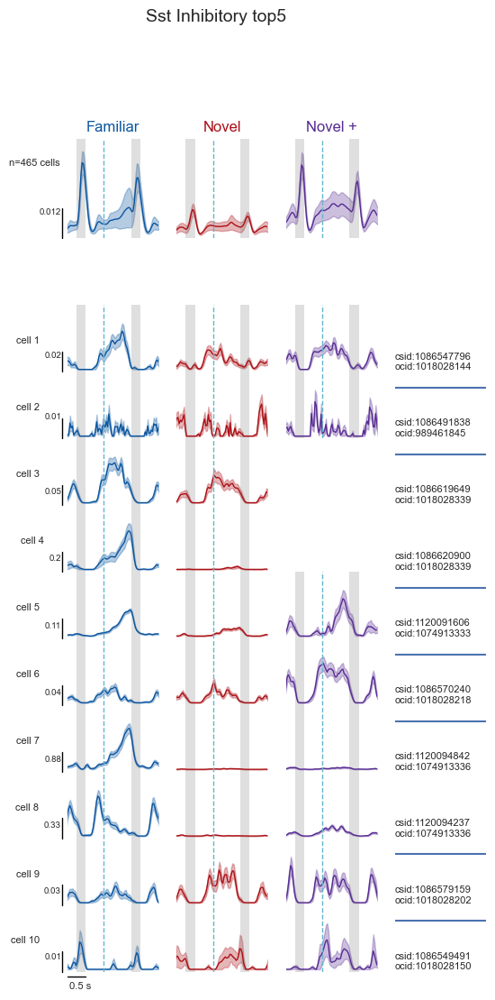

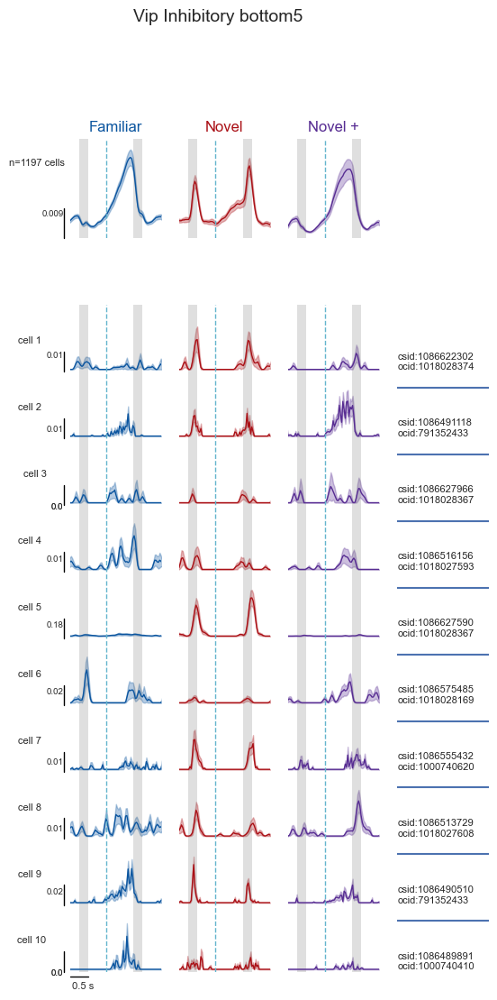

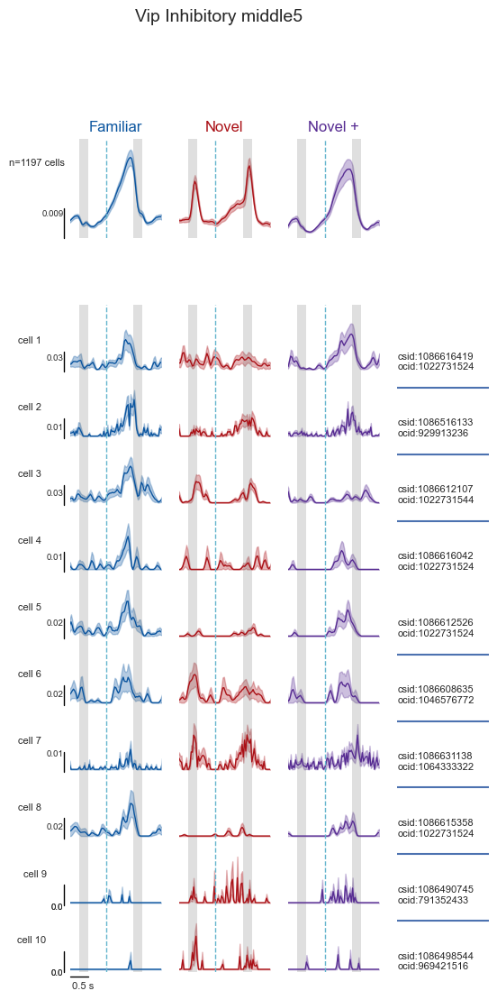

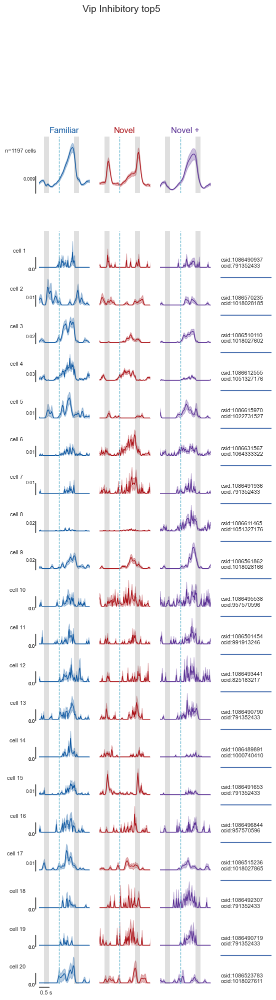

In [60]:
# Omission examples from the bottom / middle / top 5% of the omission modulation index (OMI) distribution.
# For each cell type, pool matched cell-sessions across all experience levels and take percentile bins of OMI.
# Top 5% requires fraction_significant_p_value_gray_screen > 0.1; bottom and middle 5% have no filter.
# n_cells[bin] are drawn at random (fixed seed) from the candidates in each bin.
n_cells = {'bottom5': 10, 'middle5': 10, 'top5': 20}
pct_bins = {'bottom5': (0, 5), 'middle5': (47.5, 52.5), 'top5': (95, 100)}
seed = 0
event_type = 'omissions'

omi = metrics_table[['cell_specimen_id', 'ophys_experiment_id', 'omission_modulation_index']].drop_duplicates()
assert not omi.duplicated(['cell_specimen_id', 'ophys_experiment_id']).any()
omi_df = omission_mdf.merge(omi, on=['cell_specimen_id', 'ophys_experiment_id'], how='left')
omi_df = omi_df[omi_df.cell_specimen_id.isin(matched_cells)]

omi_pct_example_cells = {}
for cell_type in utils.get_cell_types():
    ct_df = omi_df[(omi_df.cell_type == cell_type) & omi_df.omission_modulation_index.notnull()]
    for bin_name, (lo, hi) in pct_bins.items():
        lo_val, hi_val = np.percentile(ct_df.omission_modulation_index, [lo, hi])
        in_bin = ct_df[ct_df.omission_modulation_index.between(lo_val, hi_val)]
        if bin_name == 'top5':
            in_bin = in_bin[(in_bin.fraction_significant_p_value_gray_screen > 0.05)]
        else: 
            in_bin = in_bin[in_bin.reliability > 0.05]
        candidates = in_bin.cell_specimen_id.unique()
        rng = np.random.default_rng(seed)
        cells_to_plot = list(rng.choice(candidates, size=min(n_cells[bin_name], len(candidates)), replace=False))
        omi_pct_example_cells[(cell_type, bin_name)] = cells_to_plot
        print(f'{cell_type} {bin_name}: OMI [{lo_val:.2f}, {hi_val:.2f}], '
              f'{len(candidates)} candidate cells, plotting {len(cells_to_plot)}')
        if len(cells_to_plot) == 0:
            continue
        pse.plot_reliable_example_cells(omission_mdf, cells_to_plot, cell_type, event_type=event_type,
                                        save_dir=save_dir, folder='reliable_example_cells',
                                        suptitle=f'{cell_type} {bin_name}', suffix=f'_omi_{bin_name}')

#### Selected omission examples with position in the omission modulation index distribution

In [61]:
CHANGE_CELLS = {
    'Excitatory':     [1086523675, 1086512165, 1086579153],
    'Sst Inhibitory': [1120094089, 1086575280, 1086579643],
    'Vip Inhibitory': [1086627590, 1086501825, 1086615304],
}

OMISSION_CELLS = {
    'Excitatory':     [1086523675, 1086512165, 1120090119,], 
    'Sst Inhibitory': [1120094089, 1086579643, 1086569242,],                                                   # 108656942 -> 1086569242
    'Vip Inhibitory': [1086627590, 1086615304, 1086501922,]
}

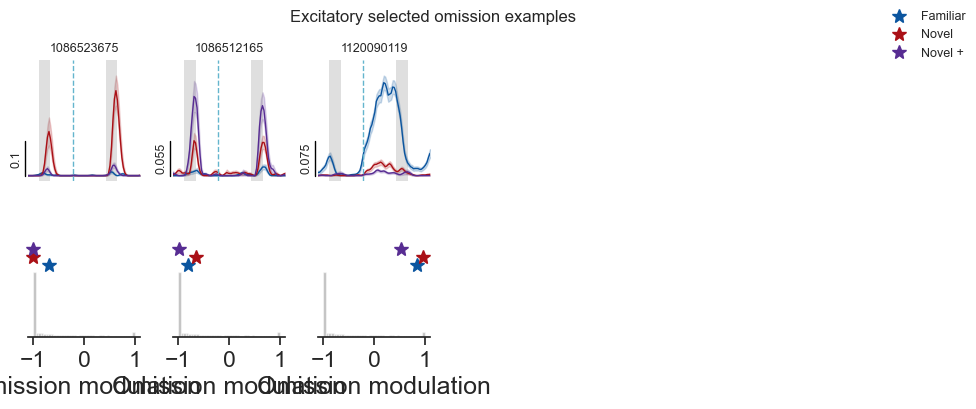

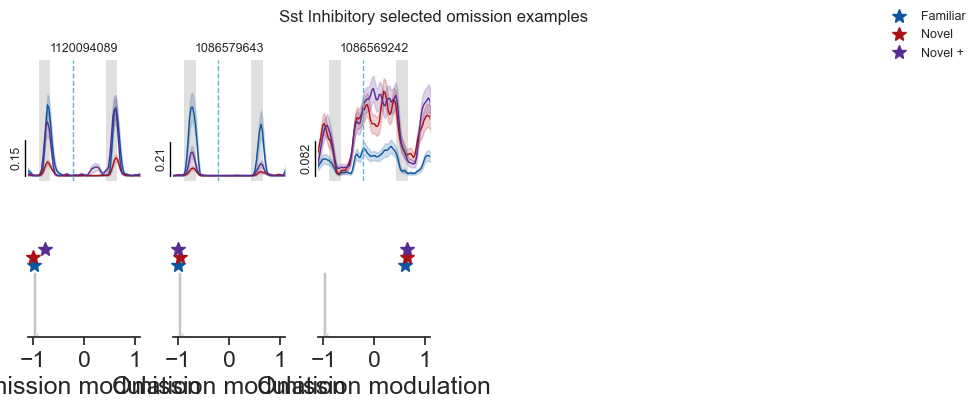

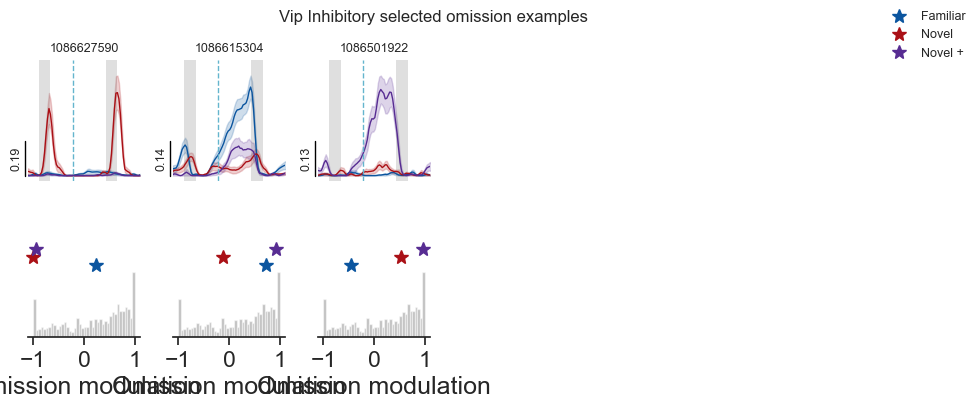

In [62]:
# Selected omission example cells in the Fig 5 style (Familiar / Novel / Novel+ overlaid), each paired with
# where the cell falls in its cell type's omission modulation index (OMI) distribution.
# Batches of 6 cells -> one 2 x 6 figure: top row = mean omission response, bottom row = pooled OMI
# distribution (matched cells, all experience levels, as used for selection) with a star per experience level
# at this cell's OMI in that session.
SELECTED_OMISSION_CELLS = {
    'Excitatory':     [1086559786, 1086512165, 1120090119, 1120133471, 1086518655, 1086557826, 1086512642, 1220092455,
                       1086543986, 1086529704, 1120092455, 1120102262, 1086571711, 1086557826,
                       1086579153, 1086523675],  # 112010262 -> 1120102262
    'Sst Inhibitory': [1120094089, 1086579643, 1086569242, 1086555222, 1086558224, 1086570240, 1120094842, 1086547796, 1086579052,
                       1120094089, 1086575280],                                                   # 108656942 -> 1086569242
    'Vip Inhibitory': [1086627590, 1086615304, 1086501922, 1086614455,  1086509065, 1086501719,  1086617472, 
                       1086673402, 1086501825, 1086627590]
}


SELECTED_OMISSION_CELLS = {
    'Excitatory':     [1086523675, 1086512165, 1120090119,], 
    'Sst Inhibitory': [1120094089, 1086579643, 1086569242,],                                                   # 108656942 -> 1086569242
    'Vip Inhibitory': [1086627590, 1086615304, 1086501922,]
}

# # THESE ARE ACTUALLY THE CHANGE CELLS
# SELECTED_OMISSION_CELLS = {
#     'Excitatory':     [1086523675, 1086512165, 1086579153],
#     'Sst Inhibitory': [1120094089, 1086575280, 1086579643],
#     'Vip Inhibitory': [1086627590, 1086501825, 1086615304],
# }



# put in change row for Sst: 1086579643,
batch_size = 6
xlim = [-1, 1.5]
EXP = utils.get_experience_levels()
exp_colors = utils.get_experience_level_colors()
omi_bin_edges = np.linspace(-1, 1, 41)

omi = metrics_table[['cell_specimen_id', 'ophys_experiment_id', 'omission_modulation_index']].drop_duplicates()
assert not omi.duplicated(['cell_specimen_id', 'ophys_experiment_id']).any()
omi_df = omission_mdf.merge(omi, on=['cell_specimen_id', 'ophys_experiment_id'], how='left')
omi_df = omi_df[omi_df.cell_specimen_id.isin(matched_cells)]


def plot_overlaid_omission_cell(ax, csid):
    """mean +/- sem omission response for each experience level, overlaid (same style as the composite)."""
    cdf = omission_mdf[omission_mdf.cell_specimen_id == csid]
    ts = None
    for e, exp in enumerate(EXP):
        d = cdf[cdf.experience_level == exp]
        if len(d) == 0:
            continue
        utils.plot_mean_trace_from_mean_df(d, ylabel='', xlabel='', xlims=xlim, alpha=0.2,
                                           color=exp_colors[e], interval_sec=1, linewidth=1, ax=ax)
        ts = d.trace_timestamps.values[0]
    if ts is not None:
        utils.plot_flashes_on_trace(ax, ts, change=False, omitted=True, alpha=0.25, linewidth=1)
    ax.set_xlim(xlim)
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(min(ymin, 0), ymax * 1.1)
    ymin, ymax = ax.get_ylim()
    bar = float(f'{ymax * .3:.2g}')
    ax.set_yticks([])
    x_bar = xlim[0] - (xlim[1] - xlim[0]) * 0.03
    ax.axvline(x=x_bar, ymin=(0 - ymin) / (ymax - ymin), ymax=(bar - ymin) / (ymax - ymin),
               color='k', linewidth=1, clip_on=False)
    ax.annotate(f'{bar:g}', xy=(x_bar, bar / 2), xycoords='data', xytext=(-2, 0), textcoords='offset points',
                rotation=90, ha='right', va='center', fontsize=9, annotation_clip=False)
    ax.set_xlabel(''); ax.set_ylabel('')
    sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
    ax.tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False)
    ax.set_xticks([])


def plot_omi_position(ax, ct_omi, csid):
    """pooled OMI histogram for the cell type + a star per experience level at this cell's OMI."""
    ax.hist(ct_omi.omission_modulation_index, bins=omi_bin_edges, density=True, color='gray', alpha=0.5)
    ymax = ax.get_ylim()[1]
    cell_rows = ct_omi[ct_omi.cell_specimen_id == csid]
    for e, exp in enumerate(EXP):
        vals = cell_rows[cell_rows.experience_level == exp].omission_modulation_index.values
        if len(vals):   # stagger stars vertically so identical values (e.g. 1) stay visible
            ax.plot(vals[0], ymax * (1.05 + 0.12 * e), marker='*', markersize=10, color=exp_colors[e],
                    clip_on=False, linestyle='')
    ax.set_xlim(-1.1, 1.1)
    ax.set_xticks([-1, 0, 1])
    ax.set_yticks([])
    ax.set_xlabel('Omission modulation')
    sns.despine(ax=ax, left=True)


for cell_type, cells in SELECTED_OMISSION_CELLS.items():
    ct_omi = omi_df[(omi_df.cell_type == cell_type) & omi_df.omission_modulation_index.notnull()]
    cells = list(dict.fromkeys(cells))                          # drop duplicate IDs, keep order
    missing = [c for c in cells if c not in set(ct_omi.cell_specimen_id)]
    if missing:
        print(f'{cell_type}: not found among matched {cell_type} cells with OMI, skipping {missing}')
    cells = [c for c in cells if c not in missing]
    for b in range(0, len(cells), batch_size):
        batch = cells[b:b + batch_size]
        figsize = (1.8 * batch_size, 3.6)
        fig, ax = plt.subplots(2, batch_size, figsize=figsize, gridspec_kw={'height_ratios': [1.3, 1]})
        for j in range(batch_size):
            if j >= len(batch):
                ax[0, j].axis('off'); ax[1, j].axis('off')
                continue
            plot_overlaid_omission_cell(ax[0, j], batch[j])
            ax[0, j].set_title(str(batch[j]), fontsize=9)
            plot_omi_position(ax[1, j], ct_omi, batch[j])
        handles = [plt.Line2D([], [], marker='*', color=c, linestyle='', markersize=10) for c in exp_colors]
        fig.legend(handles, EXP, loc='upper right', fontsize=9, frameon=False)
        fig.suptitle(f'{cell_type} selected omission examples', x=0.5, y=1.02, fontsize=12)
        fig.subplots_adjust(hspace=0.6, wspace=0.3)
        utils.save_figure(fig, figsize, save_dir, 'reliable_example_cells',
                          f'{cell_type}_omission_selected_with_omi_batch{b // batch_size + 1}')

#### Selected change example cells

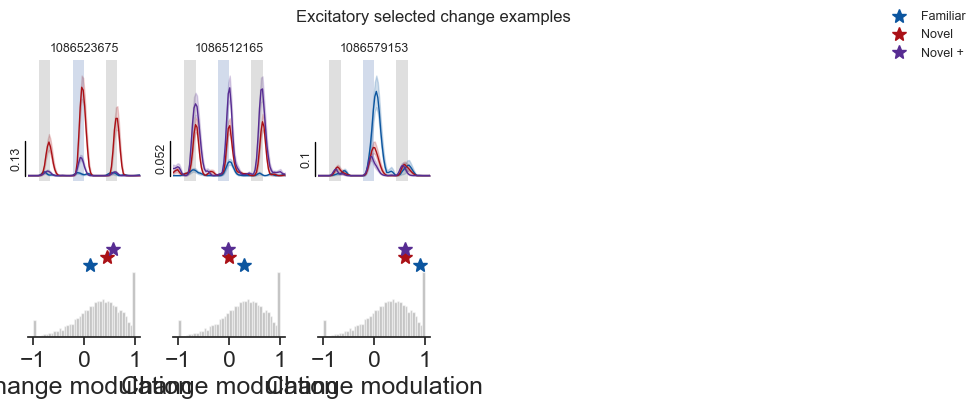

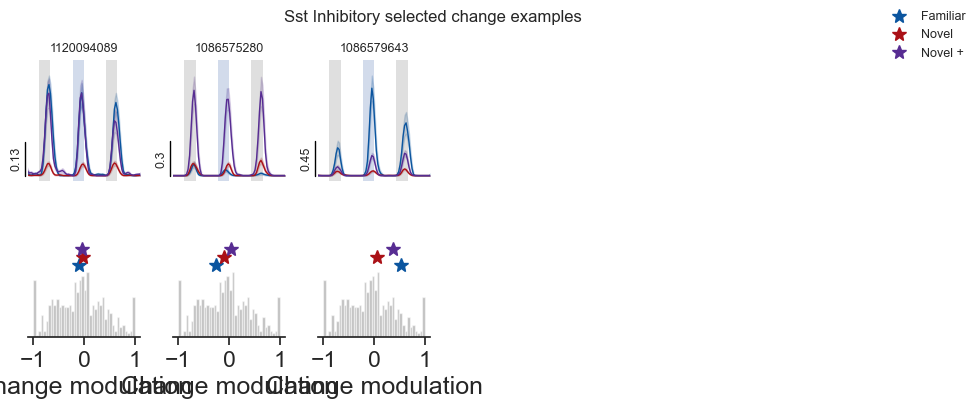

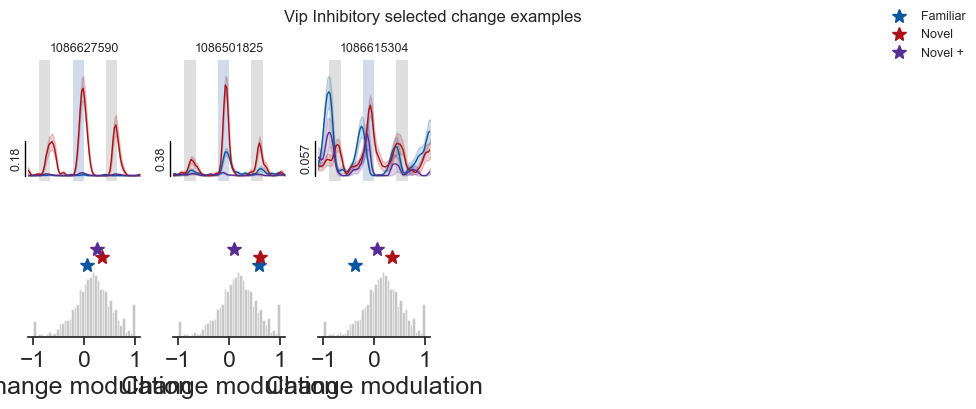

In [63]:

SELECTED_CHANGE_CELLS = {
    'Excitatory':     [1086523675, 1086512165, 1086579153],
    'Sst Inhibitory': [1120094089, 1086575280, 1086579643],
    'Vip Inhibitory': [1086627590, 1086501825, 1086615304],
}

# put in change row for Sst: 1086579643,
batch_size = 6
xlim = [-1, 1.5]
EXP = utils.get_experience_levels()
exp_colors = utils.get_experience_level_colors()
omi_bin_edges = np.linspace(-1, 1, 41)

cmi = metrics_table[['cell_specimen_id', 'ophys_experiment_id', 'change_modulation_index']].drop_duplicates()
assert not cmi.duplicated(['cell_specimen_id', 'ophys_experiment_id']).any()
cmi_df = change_mdf.merge(cmi, on=['cell_specimen_id', 'ophys_experiment_id'], how='left')
cmi_df = cmi_df[cmi_df.cell_specimen_id.isin(matched_cells)]


def plot_overlaid_change_cell(ax, csid):
    """mean +/- sem change response for each experience level, overlaid (same style as the composite)."""
    cdf = change_mdf[change_mdf.cell_specimen_id == csid]
    ts = None
    for e, exp in enumerate(EXP):
        d = cdf[cdf.experience_level == exp]
        if len(d) == 0:
            continue
        utils.plot_mean_trace_from_mean_df(d, ylabel='', xlabel='', xlims=xlim, alpha=0.2,
                                           color=exp_colors[e], interval_sec=1, linewidth=1, ax=ax)
        ts = d.trace_timestamps.values[0]
    if ts is not None:
        utils.plot_flashes_on_trace(ax, ts, change=True, omitted=False, alpha=0.25, linewidth=1)
    ax.set_xlim(xlim)
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(min(ymin, 0), ymax * 1.1)
    ymin, ymax = ax.get_ylim()
    bar = float(f'{ymax * .3:.2g}')
    ax.set_yticks([])
    x_bar = xlim[0] - (xlim[1] - xlim[0]) * 0.03
    ax.axvline(x=x_bar, ymin=(0 - ymin) / (ymax - ymin), ymax=(bar - ymin) / (ymax - ymin),
               color='k', linewidth=1, clip_on=False)
    ax.annotate(f'{bar:g}', xy=(x_bar, bar / 2), xycoords='data', xytext=(-2, 0), textcoords='offset points',
                rotation=90, ha='right', va='center', fontsize=9, annotation_clip=False)
    ax.set_xlabel(''); ax.set_ylabel('')
    sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
    ax.tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False)
    ax.set_xticks([])


def plot_cmi_position(ax, ct_omi, csid):
    """pooled CMI histogram for the cell type + a star per experience level at this cell's CMI."""
    ax.hist(ct_omi.change_modulation_index, bins=omi_bin_edges, density=True, color='gray', alpha=0.5)
    ymax = ax.get_ylim()[1]
    cell_rows = ct_omi[ct_omi.cell_specimen_id == csid]
    for e, exp in enumerate(EXP):
        vals = cell_rows[cell_rows.experience_level == exp].change_modulation_index.values
        if len(vals):   # stagger stars vertically so identical values (e.g. 1) stay visible
            ax.plot(vals[0], ymax * (1.05 + 0.12 * e), marker='*', markersize=10, color=exp_colors[e],
                    clip_on=False, linestyle='')
    ax.set_xlim(-1.1, 1.1)
    ax.set_xticks([-1, 0, 1])
    ax.set_yticks([])
    ax.set_xlabel('Change modulation')
    sns.despine(ax=ax, left=True)


for cell_type, cells in SELECTED_CHANGE_CELLS.items():
    ct_omi = cmi_df[(cmi_df.cell_type == cell_type) & cmi_df.change_modulation_index.notnull()]
    cells = list(dict.fromkeys(cells))                          # drop duplicate IDs, keep order
    missing = [c for c in cells if c not in set(ct_omi.cell_specimen_id)]
    if missing:
        print(f'{cell_type}: not found among matched {cell_type} cells with OMI, skipping {missing}')
    cells = [c for c in cells if c not in missing]
    for b in range(0, len(cells), batch_size):
        batch = cells[b:b + batch_size]
        figsize = (1.8 * batch_size, 3.6)
        fig, ax = plt.subplots(2, batch_size, figsize=figsize, gridspec_kw={'height_ratios': [1.3, 1]})
        for j in range(batch_size):
            if j >= len(batch):
                ax[0, j].axis('off'); ax[1, j].axis('off')
                continue
            plot_overlaid_change_cell(ax[0, j], batch[j])
            ax[0, j].set_title(str(batch[j]), fontsize=9)
            plot_cmi_position(ax[1, j], ct_omi, batch[j])
        handles = [plt.Line2D([], [], marker='*', color=c, linestyle='', markersize=10) for c in exp_colors]
        fig.legend(handles, EXP, loc='upper right', fontsize=9, frameon=False)
        fig.suptitle(f'{cell_type} selected change examples', x=0.5, y=1.02, fontsize=12)
        fig.subplots_adjust(hspace=0.6, wspace=0.3)
        utils.save_figure(fig, figsize, save_dir, 'reliable_example_cells',
                          f'{cell_type}_change_selected_with_cmi_batch{b // batch_size + 1}')

#### Across cre examples for omissions

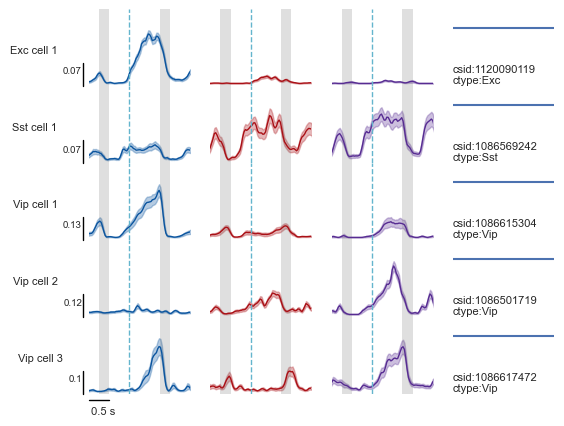

In [64]:
cells_to_plot = [1120090119, # Exc
                 1086569242, # Sst
                 1086615304, # Vip
                 1086501719, # Vip
                 1086617472, # Vip
                ]
event_type = 'omissions'

pse.plot_selected_cell_examples(omission_mdf, cells_to_plot, event_type=event_type,
                                xlim_seconds=[-1, 1.5], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_omissions')
    

#### Plot ROI zoom for example cells 

In [65]:
%load_ext autoreload
%autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [66]:
# cells_to_plot = [1120090119, # Exc
#                  1086569242, # Sst
#                  1086615304, # Vip
#                  1086501719, # Vip
#                  1086617472, # Vip
#                 ]

# cell_specimen_id = cells_to_plot[0]

# for cell_specimen_id in cells_to_plot:
#     pse.plot_matched_roi_mask_zoom(cell_specimen_id, platform_cells_table, platform_experiments, save_dir=save_dir)
    

### Matched cell examples

cell_specimen_id: 1086514606
experience_level: Familiar
ophys_experiment_id: 989213060


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel
ophys_experiment_id: 990400778


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel +
ophys_experiment_id: 991852002


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

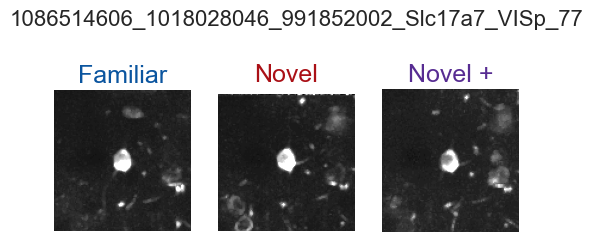

In [67]:
cell_specimen_id = 1086514606 #Excitatory behavior coding cell

pse.plot_matched_rois(cell_specimen_id, platform_cells_table,
                                        folder='matched_rois', save_dir=None)

cell_specimen_id: 1086628708
experience_level: Familiar
ophys_experiment_id: 882551935


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel
ophys_experiment_id: 882968564


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel +
ophys_experiment_id: 885146239


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

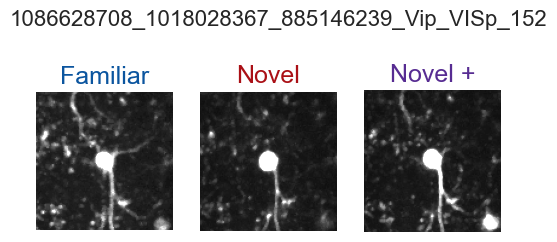

In [68]:
cell_specimen_id = 1086628708  

pse.plot_matched_rois(cell_specimen_id, platform_cells_table,
                                        folder='matched_rois', save_dir=None)

cell_specimen_id: 1086551540
experience_level: Familiar
ophys_experiment_id: 850517352


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel
ophys_experiment_id: 853363749


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel +
ophys_experiment_id: 854759900


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

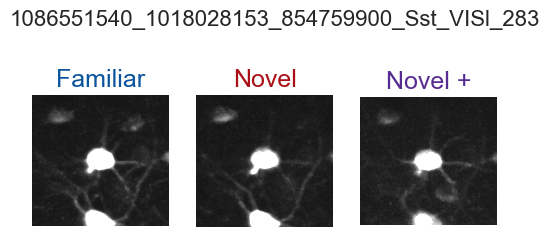

In [69]:
cell_specimen_id = 1086551540  

pse.plot_matched_rois(cell_specimen_id, platform_cells_table,
                                        folder='matched_rois', save_dir=None)

cell_specimen_id: 1086501719
experience_level: Familiar
ophys_experiment_id: 847267622


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel
ophys_experiment_id: 849233396


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel +
ophys_experiment_id: 851085100


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

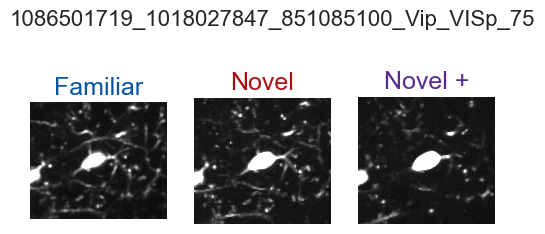

In [70]:
cell_specimen_id = 1086501719

pse.plot_matched_rois(cell_specimen_id, platform_cells_table,
                                        folder='matched_rois', save_dir=None)

#### ROIs and traces across sessions

In [71]:
ophys_container_id = 835006071 
ophys_container_id = 829561794

In [72]:
# cell_type = 'Excitatory'

# # Get high SNR matched cells for container
# matched_cells_snr, dff_metrics = pse.get_high_snr_matched_cells_for_container(ophys_container_id, dataset_dict,
#                                                                                matched_cells_table, platform_experiments, 
#                                                                                )

# # Plot matched max projections for container
# # Note: function signature is (ophys_container_id, platform_experiments, dataset_dict, save_dir, ax)
# # matched_cells_table is NOT a parameter
# pse.plot_matched_max_projections_for_container(ophys_container_id, platform_experiments,
#                                               dataset_dict,
#                                               save_dir=save_dir, ax=None)



In [73]:
# n_reliable_cells_threshold = 5

# reliable_cells = change_mdf[(change_mdf.fraction_significant_p_value_gray_screen>0.15) & 
#             (change_mdf.mean_response > 0.02) &
#             (change_mdf.cell_type==cell_type) & 
#             (change_mdf.ophys_experiment_id.isin(platform_experiments.index.unique()))]

# # reliable_cells = pd.concat([reliable_cells_changes, reliable_cells_omissions])
# matched_reliable_cells = reliable_cells[reliable_cells.cell_specimen_id.isin(matched_cells_table.cell_specimen_id.unique())]


In [74]:
# start_times = np.asarray([512])
# duration_seconds = 18

# matched_cells = matched_reliable_cells[matched_reliable_cells.ophys_container_id==ophys_container_id]
# matched_cells = matched_cells.sort_values(by='fraction_significant_p_value_gray_screen', ascending=False)
# matched_cells = matched_cells.drop_duplicates(subset='cell_specimen_id')
# matched_cells = matched_cells.cell_specimen_id.values
# print(len(matched_cells))

In [75]:
# start_times = np.asarray([513])

# csids = [1086502440, 
#          1086500171,
#          1086502886,
#          1086501666, 
#          1086529369]

# pse.plot_matched_rois_and_traces_for_container(ophys_container_id, dataset_dict,
#                                         matched_cells_table, platform_experiments, fontsize=12,
#                                         start_times=start_times, duration_seconds=18,
#                                         matched_cells=csids, save_dir=save_dir, suffix='')

In [76]:

# suffix = '_reliable_cells_selected'

# pse.plot_matched_traces_across_sessions(ophys_container_id, dataset_dict, 
#                                     matched_cells_table, platform_experiments, 
#                                     change_mdf, omission_mdf, cell_type, skip_behavior=True,
#                                     start_times=start_times, duration_seconds=duration_seconds,
#                                     matched_cells=matched_cells, save_dir=save_dir, suffix=suffix)

In [77]:
from visual_behavior.visualization.panel_grid import (
    fig_setup, panel, show_label_gutters, show_decoration_zones,
    check_label_overlap, auto_fit_left, snug_left_to_gutter, snug_top_to_gutter, auto_fit_bottom,
)


In [78]:
# Set cells 

# original, matching first two columns 
# CHANGE_CELLS = {
#     'Excitatory':     [1086523675, 1086512165, 1086579153],
#     'Sst Inhibitory': [1120094089, 1086579643, 1086575280],
#     'Vip Inhibitory': [1086627590, 1086615304, 1086501825],
# }

# OMISSION_CELLS = {
#     'Excitatory':     [1086523675, 1086512165, 1120090119],
#     'Sst Inhibitory': [1120094089, 1086579643, 1086569242],
#     'Vip Inhibitory': [1086627590, 1086615304, 1086501922],
# }

# example cells per cell-type row (final picks; omission cells chosen with reference to the OMI distribution)
CHANGE_CELLS = {
    'Excitatory':     [1086579153, 1086512165, 1086523675],
    'Sst Inhibitory': [1086579643, 1120094089, 1086575280],
    'Vip Inhibitory': [1086615304, 1086627590, 1086501825],
}

# original, matc
OMISSION_CELLS = {
    'Excitatory':     [1086579153, 1086512165, 1120090119],
    'Sst Inhibitory': [1086579643, 1120094089, 1086569242],
    'Vip Inhibitory': [1086615304, 1086627590, 1086501922],
}
# example-cell column titles: cells 1-2 are the same in both panels; the omission panel's 3rd column is a different cell
EX_COL_LABELS = {'changes': ['Cell 1', 'Cell 2', 'Cell 3'],
                 'omissions': ['Cell 1', 'Cell 2', 'Cell 4']}


## Figure 3 composite — Impact of novelty and familiarization on excitatory, Vip, and Sst inhibitory subclasses (final layout, v3)
Left column = image change (A, B+C, D), right column = image omission (E, F+G, H); schematics above each column. Saves as `figure_3_main_composite_v3`. Run the data-loading and per-panel cells above first, then the import cell, the example-cell selection cell, and this composite cell.
Alternative layouts (original, v2, v4, v5) are in `figure_3_main_alternative_layouts.ipynb`.

figsize = (9.28, 15.38); trace axes = 1.15 x 1.15 in; B/C width = 1.20 in
Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers
Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=e

Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers
Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=e

letter overlaps: none


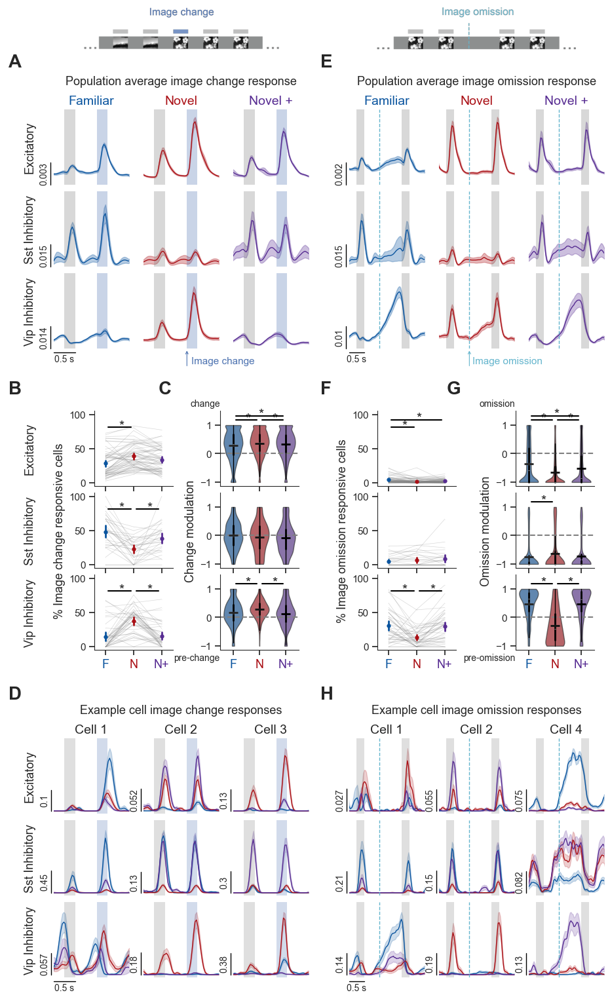

In [79]:
# Composite Figure 3 main (COLUMN LAYOUT, v3) - alternative to v2 (v2 cell above is unchanged)
#   Left column = image change, right column = image omission; 3 sections per column:
#     row 1:  A / E  population averages (cell types x Familiar/Novel/Novel+)
#     row 2:  B + C / F + G  % responsive | modulation index (side by side)
#     row 3:  D / H  example cells (Familiar/Novel/Novel+ overlaid)
#   Cell-type labels sit left of A/E and D/H at the same offset (no "n = x cells"; put n in the legend).
#   Change / omission schematic centered above each column.
#
# Geometry is in INCHES (knobs below); every axes is placed explicitly. panel() is used for letters /
# axes ownership; letters are then placed from the rendered content (left of it, aligned per figure row).
#
# UPSTREAM (run the data-loading cells above first): data_type, change_mdf, omission_mdf,
#   each_image_mdf, metrics_table, save_dir, and the ppf / utils imports.
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from visual_behavior.visualization.panel_grid import fig_setup, panel

# ---------------------------------------------------------------- knobs ----
TRACE_W_IN = 1.15           # width of every A/E/D/H trace axes; FIG_W is derived from it
CHANGE_XLIM = [-1, 0.75]
OMISSION_XLIM = [-1, 1.5]


GUT = (20, 28)              # panel() letter gutter (pt) - only used for the initial letter axes
# horizontal (inches)
COLUMN_GAP_IN = 0.20        # gap between the change and omission columns
RIGHT_MARGIN_IN = 0.10
LEFT_SETBACK_IN = [0.78, 0.42]  # column left -> first trace spine: change col (letter + cell-type label + scale)
                                #   / omission col (letter + scale value only; no cell-type labels)
TRACE_GAP_IN = 0.22         # gap between trace columns (same in A/E and D/H so their columns line up)
PCT_SETBACK_IN = [1.40, 0.85]  # column left -> B / F spine (B also holds the cell-type labels)
BC_W_IN = 1.20              # B/C/F/G axes width (C/G are right-aligned in the column; the rest is B|C gap)
BC_RIGHT_PAD_IN = 0.15      # space right of C/G
# vertical (inches)
TOP_IN = 0.02
TRACE_ROW_IN = 1.15         # row height in A/E and D/H
BC_ROW_IN = 1.15            # row height in B/C/F/G
ROW_GAP_IN = 0.10
TRACE_HEADER_IN = 0.80      # A/E and D/H: block title + column titles above row 1
BC_HEADER_IN = 0.40         # B+C / F+G: room for letters + 'change' text above row 1
BOTTOM_IN = 0.45            # below last row: tick labels / scale bar / event arrow
SECTION_GAP_IN = 0.10
TITLE_GAP_IN = 0.34         # block-title baseline sits this far above row 1
SCHEM_MAX_H_IN = 0.70       # schematic height cap (actual height follows the PNG aspect)
SCHEM_W_FRAC = 0.80         # schematic width as a fraction of the A/E trace span
SCHEM_PAD_IN = 0.08         # space below/above the schematic
LETTER_PAD_IN = 0.04
LETTER_GAP_IN = 0.04

# text
CT_FS = 13                  # = AXIS_LABEL_FS (matches the other y labels)
CT_OFFSET_PT = 26           # cell-type label offset left of the first spine (same for A/E and D/H)
AXIS_LABEL_FS, TICK_FS = 13, 11
SPINE_LW = 0.8
EXP_TITLE_FS = 14
INFO_TITLE_FS = 13
SCALE_FS = 10
TIME_BAR_FRAC = 0.05        # 0.5 s bar: distance below the x-axis, as a fraction of the y range
MOD_ANNOT_FS = 10
ARROW_LW, ARROW_SCALE = 0.8, 7
TRACE_LW = 1

CHANGE_COLOR = sns.color_palette()[0]
OMISSION_COLOR = sns.color_palette()[9]
TITLE_POP = {'changes': 'Population average image change response',
             'omissions': 'Population average image omission response'}
TITLE_EX = {'changes': 'Example cell image change responses',
            'omissions': 'Example cell image omission responses'}
SCHEMATIC_DIR = '/Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/schematics/Figure 1'
SCHEM = {'changes': os.path.join(SCHEMATIC_DIR, 'image_change_small.png'),
         'omissions': os.path.join(SCHEMATIC_DIR, 'image_omission_small.png')}
SCHEM_IMG = {}
for _k, _f in SCHEM.items():
    try:
        SCHEM_IMG[_k] = plt.imread(_f)
    except Exception as e:
        SCHEM_IMG[_k] = None
        print('could not load schematic', _f, ':', e)

EXP = utils.get_experience_levels()
exp_colors = utils.get_experience_level_colors()
cell_types = ['Excitatory', 'Sst Inhibitory', 'Vip Inhibitory']

# ---------------------------------------------------------------- geometry ----
n_ex_cols = 3
SPAN_IN = n_ex_cols * TRACE_W_IN + (n_ex_cols - 1) * TRACE_GAP_IN            # A/E/D/H trace span (same in both columns)
COL_W = [LEFT_SETBACK_IN[c] + SPAN_IN for c in range(2)]                      # column widths
COL_X = [0.0, COL_W[0] + COLUMN_GAP_IN]                                       # column left edges
FIG_W = round(COL_X[1] + COL_W[1] + RIGHT_MARGIN_IN, 2)

SCHEM_H = {k: (min(SCHEM_MAX_H_IN, SCHEM_W_FRAC * SPAN_IN * im.shape[0] / im.shape[1]) if im is not None
               else SCHEM_MAX_H_IN) for k, im in SCHEM_IMG.items()}
SCHEM_BAND_IN = max(SCHEM_H.values()) + 2 * SCHEM_PAD_IN

ROW_H = {'pop': TRACE_ROW_IN, 'bc': BC_ROW_IN, 'ex': TRACE_ROW_IN}
ROWS_H_IN = {k: 3 * v + 2 * ROW_GAP_IN for k, v in ROW_H.items()}
SEC_H = {'pop': TRACE_HEADER_IN + ROWS_H_IN['pop'] + BOTTOM_IN,
         'bc': BC_HEADER_IN + ROWS_H_IN['bc'] + BOTTOM_IN,
         'ex': TRACE_HEADER_IN + ROWS_H_IN['ex'] + BOTTOM_IN}
SEC_Y = {'pop': TOP_IN + SCHEM_BAND_IN}
SEC_Y['bc'] = SEC_Y['pop'] + SEC_H['pop'] + SECTION_GAP_IN
SEC_Y['ex'] = SEC_Y['bc'] + SEC_H['bc'] + SECTION_GAP_IN
SEC_HDR = {'pop': TRACE_HEADER_IN, 'bc': BC_HEADER_IN, 'ex': TRACE_HEADER_IN}
FIG_H = round(SEC_Y['ex'] + SEC_H['ex'], 2)
print(f'figsize = ({FIG_W}, {FIG_H}); trace axes = {TRACE_W_IN:.2f} x {TRACE_ROW_IN:.2f} in; B/C width = {BC_W_IN:.2f} in')

def _fx(x_in): return x_in / FIG_W
def _fy(y_in): return y_in / FIG_H

def _place(ax, x_in, w_in, sec, r):
    top = SEC_Y[sec] + SEC_HDR[sec] + r * (ROW_H[sec] + ROW_GAP_IN)
    ax.set_position([_fx(x_in), 1 - _fy(top + ROW_H[sec]), _fx(w_in), _fy(ROW_H[sec])])

def _trace_x(c, j):
    return COL_X[c] + LEFT_SETBACK_IN[c] + j * (TRACE_W_IN + TRACE_GAP_IN)

LETTERS = {'changes': ('A', 'B', 'C', 'D'), 'omissions': ('E', 'F', 'G', 'H')}
LETTER_ROWS = [('A', 'E'), ('B', 'C', 'F', 'G'), ('D', 'H')]
REGIONS = {}
for c, ev in enumerate(['changes', 'omissions']):
    la, lb, lc, ld = LETTERS[ev]
    x0, x1 = COL_X[c], COL_X[c] + COL_W[c]
    xm = x0 + PCT_SETBACK_IN[c] + BC_W_IN + 0.1                    # B|C region split (letters are placed from content)
    for l, sec, a, b in [(la, 'pop', x0, x1), (lb, 'bc', x0, xm), (lc, 'bc', xm, x1), (ld, 'ex', x0, x1)]:
        REGIONS[l] = [_fx(a), _fx(b), _fy(SEC_Y[sec]), _fy(SEC_Y[sec] + SEC_H[sec])]

# ---------------------------------------------------------------- helpers ----
def _cell_type_label(ax, cell_type):
    ax.annotate(cell_type, xy=(0, 0.5), xycoords='axes fraction', xytext=(-CT_OFFSET_PT, 0),
                textcoords='offset points', rotation=90, fontsize=CT_FS, ha='center', va='center',
                annotation_clip=False)

def _event_arrow(ax, label, color):
    ax.annotate(label, xy=(0.12, -0.1), xycoords=ax.get_xaxis_transform(),
                ha='left', va='top', color=color, fontsize=11, clip_on=False)
    ax.annotate('', xy=(0.01, -0.25), xycoords=ax.get_xaxis_transform(), xytext=(0.01, 0),
                arrowprops=dict(arrowstyle='<-', color=color, lw=ARROW_LW, mutation_scale=ARROW_SCALE),
                clip_on=False)

def _time_bar(ax, xlim, seconds=0.5):
    ymn, ymx = ax.get_ylim()
    xfrac = seconds / (xlim[1] - xlim[0])
    y_bar = ymn - (ymx - ymn) * TIME_BAR_FRAC
    ax.axhline(y=y_bar, xmin=0, xmax=xfrac, color='k', linewidth=1, clip_on=False)
    ax.annotate(f'{seconds} s', xy=(xlim[0] + seconds / 2, y_bar), xycoords='data', xytext=(0, -2),
                textcoords='offset points', ha='center', va='top', fontsize=SCALE_FS,
                clip_on=False, annotation_clip=False)

def plot_pop_avg_block(axgrid, mdf, event_type, xlim, arrow_label, arrow_color, labels=True):
    dist = (xlim[1] - xlim[0]) * 0.04
    for i, cell_type in enumerate(cell_types):
        row = list(axgrid[i])
        df_ct = mdf[mdf.cell_type == cell_type]
        ppf.plot_population_averages_for_conditions(
            df_ct, data_type, event_type, 'experience_level', 'experience_level',
            horizontal=True, legend=False, xlim_seconds=xlim, interval_sec=1,
            palette=exp_colors, ax=row)
        scale = 1.06 if cell_type == 'Excitatory' else 1.15
        _, ymax = row[0].get_ylim(); row[0].set_ylim(0, ymax * scale)
        _, ymax = row[0].get_ylim()
        row[0].set_yticks([])
        row[0].axvline(x=xlim[0] - dist, ymin=0, ymax=0.3, color='k', linewidth=1, clip_on=False)
        row[0].annotate(f'{np.round(ymax * .3, 3):g}', xy=(xlim[0] - dist, ymax * .15), xycoords='data',
                        xytext=(-2, 0), textcoords='offset points', rotation=90, ha='right', va='center',
                        fontsize=SCALE_FS, annotation_clip=False)   # rotated, like D/H
        row[0].set_ylabel('')
        if labels:
            _cell_type_label(row[0], cell_type)
        for j in range(3):
            row[j].set_title(EXP[j] if i == 0 else '', color=exp_colors[j], fontsize=EXP_TITLE_FS)
            row[j].set_xlabel('')
        sns.despine(ax=row[0], top=True, right=True, left=True, bottom=True)
        row[0].tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False)
        row[0].set_xticks([])
        for j in (1, 2):
            row[j].axis('off')
        if i == len(cell_types) - 1:
            _event_arrow(row[1], arrow_label, arrow_color)
            _time_bar(row[0], xlim)

def plot_overlaid_cell(ax, mdf, csid, event_type, xlim):
    change, omitted = event_type == 'changes', event_type == 'omissions'
    cdf = mdf[mdf.cell_specimen_id == csid]
    ts = None
    for e, exp in enumerate(EXP):
        d = cdf[cdf.experience_level == exp]
        if len(d) == 0:
            continue
        utils.plot_mean_trace_from_mean_df(d, ylabel='', xlabel='', xlims=xlim, alpha=0.2,
                                           color=exp_colors[e], interval_sec=1, linewidth=TRACE_LW, ax=ax)
        ts = d.trace_timestamps.values[0]
    if ts is not None:
        utils.plot_flashes_on_trace(ax, ts, change=change, omitted=omitted, alpha=0.25, linewidth=TRACE_LW)
    ax.set_xlim(xlim)
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(min(ymin, 0), ymax * 1.1)
    ymin, ymax = ax.get_ylim()
    bar = float(f'{ymax * .3:.2g}')
    ax.set_yticks([])
    x_bar = xlim[0] - (xlim[1] - xlim[0]) * 0.03
    ax.axvline(x=x_bar, ymin=(0 - ymin) / (ymax - ymin), ymax=(bar - ymin) / (ymax - ymin),
               color='k', linewidth=1, clip_on=False)
    ax.annotate(f'{bar:g}', xy=(x_bar, bar / 2), xycoords='data', xytext=(-2, 0), textcoords='offset points',
                rotation=90, ha='right', va='center', fontsize=SCALE_FS, annotation_clip=False)
    ax.set_xlabel(''); ax.set_ylabel('')
    sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
    ax.tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False, pad=-1)
    ax.set_xticks([])

def plot_example_block(grid, mdf, cells_by_type, event_type, xlim, labels=True):
    for i, cell_type in enumerate(cell_types):
        cells = cells_by_type.get(cell_type, [])
        for j in range(grid.shape[1]):
            if j < len(cells):
                plot_overlaid_cell(grid[i, j], mdf, cells[j], event_type, xlim)
            else:
                grid[i, j].axis('off')
        if labels:
            _cell_type_label(grid[i, 0], cell_type)     # label even if this row has no cell in column 0
    _time_bar(grid[-1, 0], xlim)

def style_small(axs):
    for _a in axs:
        _a.set_title('')
        _a.tick_params(labelsize=TICK_FS)
        _a.tick_params(axis='x', labelsize=TICK_FS + 2)
        for _s in _a.spines.values():
            _s.set_linewidth(SPINE_LW)
    for _a in axs[:-1]:
        _a.tick_params(labelbottom=False); _a.set_xlabel('')
    axs[1].yaxis.label.set_size(AXIS_LABEL_FS)

# ---------------------------------------------------------------- figure ----
fig = plt.figure(figsize=(FIG_W, FIG_H)); fig_setup(fig)
stats_dir = os.path.join(save_dir, 'composite', 'figure_3_v3_stats') if save_dir else None
if stats_dir:
    os.makedirs(stats_dir, exist_ok=True)

each_change_pref = each_image_mdf[(each_image_mdf.is_change == True) & (each_image_mdf.pref_stim == True)]
COLS = [  # event, mdf, xlim, pct df, threshold, pct ylabel, examples, arrow, modulation
    ('changes', change_mdf, CHANGE_XLIM, each_change_pref, 0.2, '% Image change responsive cells',
     CHANGE_CELLS, ('Image change', CHANGE_COLOR), ('change_modulation_index', 'Change modulation', ('pre-change', 'change'))),
    ('omissions', omission_mdf, OMISSION_XLIM, omission_mdf, 0.1, '% Image omission responsive cells',
     OMISSION_CELLS, ('Image omission', OMISSION_COLOR), ('omission_modulation_index', 'Omission modulation', ('pre-omission', 'omission'))),
]
header_texts = {}
for c, (ev, mdf, xlim, pct_df, thr, pct_ylabel, cells, arrow, mod) in enumerate(COLS):
    la, lb, lc, ld = LETTERS[ev]
    # --- A/E population averages ---
    gp = np.array(panel(fig, REGIONS[la][:2], REGIONS[la][2:], la, dim=(3, 3), sharey='row', gutter_pt=GUT), dtype=object)
    for i in range(3):
        for j in range(3):
            _place(gp[i, j], _trace_x(c, j), TRACE_W_IN, 'pop', i)
    plot_pop_avg_block(gp, mdf, ev, xlim, *arrow, labels=(c == 0))   # cell-type labels on the change column only
    # --- B/F % responsive ---
    ab = list(np.atleast_1d(panel(fig, REGIONS[lb][:2], REGIONS[lb][2:], lb, dim=(3, 1), sharex=True, gutter_pt=GUT)))
    xb = COL_X[c] + PCT_SETBACK_IN[c]
    for i in range(3):
        _place(ab[i], xb, BC_W_IN, 'bc', i)
    ppf.plot_percent_responsive_cells(pct_df, responsiveness_threshold=thr, ylim=(-5, 105), ylabel=pct_ylabel,
                                      horizontal=False, event_type=ev, stats_dir=stats_dir, ax=ab)
    style_small(ab)
    if c == 0:   # cell-type labels for the B+C row, at the same x as A/D's labels
        _ct_x = _fx(_trace_x(0, 0)) - CT_OFFSET_PT / 72.0 / FIG_W
        for i, cell_type in enumerate(cell_types):
            ab[i].annotate(cell_type, xy=(_ct_x, 0.5), xycoords=(fig.transFigure, ab[i].transAxes),
                           rotation=90, fontsize=CT_FS, ha='center', va='center', annotation_clip=False)
    # --- C/G modulation index ---
    ac = list(np.atleast_1d(panel(fig, REGIONS[lc][:2], REGIONS[lc][2:], lc, dim=(3, 1), sharex=True, gutter_pt=GUT)))
    xc = COL_X[c] + COL_W[c] - BC_RIGHT_PAD_IN - BC_W_IN          # C/G right-aligned in the column
    for i in range(3):
        _place(ac[i], xc, BC_W_IN, 'bc', i)
    metric, mod_label, annot = mod
    ppf.plot_modulation_index_distribution(metrics_table, metric, label=mod_label, lims=(-1.15, 1.15),
                                           horiz=False, annot=annot, metric_on_y=True, abbreviate_exp=True,
                                           fill=True, event_type=ev, stats_dir=stats_dir, ax=ac)
    style_small(ac)
    for _a in ac:
        for _t in _a.texts:
            if _t.get_text() in annot:
                _t.set_fontsize(MOD_ANNOT_FS)
    # --- D/H example cells ---
    gx = np.array(panel(fig, REGIONS[ld][:2], REGIONS[ld][2:], ld, dim=(3, n_ex_cols), gutter_pt=GUT),
                  dtype=object).reshape(3, n_ex_cols)
    for i in range(3):
        for j in range(n_ex_cols):
            _place(gx[i, j], _trace_x(c, j), TRACE_W_IN, 'ex', i)
    plot_example_block(gx, mdf, cells, ev, xlim, labels=(c == 0))
    for j in range(n_ex_cols):
        gx[0, j].set_title(EX_COL_LABELS[ev][j], fontsize=EXP_TITLE_FS)

    # --- headers: block titles + schematic above the column ---
    xs0, xs1 = _trace_x(c, 0), _trace_x(c, n_ex_cols - 1) + TRACE_W_IN
    for l, sec, title in [(la, 'pop', TITLE_POP[ev]), (ld, 'ex', TITLE_EX[ev])]:
        ty = SEC_Y[sec] + SEC_HDR[sec] - TITLE_GAP_IN
        header_texts[l] = fig.text(_fx((xs0 + xs1) / 2), 1 - _fy(ty), title, ha='center', va='bottom',
                                   fontsize=INFO_TITLE_FS)
    sw = SCHEM_W_FRAC * SPAN_IN
    sax = fig.add_axes([_fx((xs0 + xs1 - sw) / 2), 1 - _fy(TOP_IN + SCHEM_PAD_IN + SCHEM_H[ev]),
                        _fx(sw), _fy(SCHEM_H[ev])])
    if SCHEM_IMG[ev] is not None:
        sax.imshow(SCHEM_IMG[ev])
        sax.set_anchor('S')
    sax.axis('off')
    sax._panel_grid_label_ax = True    # not a panel; skip in letter placement / audit

# ---- panel letters: left of each panel's leftmost content, just above its top, aligned per figure row ----
for _lax in fig.axes:
    if getattr(_lax, '_panel_grid_label_ax', False):
        for _lt in _lax.texts:
            _lt.set_fontsize(20)
fig.canvas.draw()
_r = fig.canvas.get_renderer()
_inv = fig.transFigure.inverted()
_letter_pos = {}
for _lax in fig.axes:
    if not getattr(_lax, '_panel_grid_label_ax', False) or not _lax.texts:
        continue
    _lbl = _lax.texts[0].get_text()
    if _lbl not in REGIONS:
        continue
    _owned = [a for a in fig.axes if getattr(a, '_panel_grid_owner', None) == _lbl and a.get_visible()
              and (a.has_data() or a.texts or a.get_title())]
    _bbs = [a.get_tightbbox(_r).transformed(_inv) for a in _owned]
    if not _bbs:
        continue
    _tops = [bb.y1 for bb in _bbs]
    if _lbl in header_texts:
        _tops.append(header_texts[_lbl].get_window_extent(_r).transformed(_inv).y1)
    _p = _lax.get_position()
    _wl = _lax.texts[0].get_window_extent(_r).transformed(_inv).width
    _x = max(-0.15 * _p.width, min(bb.x0 for bb in _bbs) - _fx(LETTER_GAP_IN) - _wl - 0.15 * _p.width)
    _letter_pos[_lbl] = (_lax, _x, max(_tops) + _fy(LETTER_PAD_IN) - _p.height * 0.2)
for _row in LETTER_ROWS:                     # same height across a figure row (highest of the row)
    _y = max(_letter_pos[l][2] for l in _row if l in _letter_pos)
    for l in _row:
        if l in _letter_pos:
            _lax, _x, _ = _letter_pos[l]
            _p = _lax.get_position()
            _lax.set_position([_x, _y, _p.width, _p.height])
# B/F letters share the x of A/D (E/H); then every B/C/F/G plot is pushed right (if needed) so its
# leftmost content (y label, ticks, 'pre-change' text) starts right of its own letter
for _top, _mid in [('A', 'B'), ('E', 'F')]:
    _lax, _, _ = _letter_pos[_mid]
    _p = _lax.get_position()
    _lax.set_position([_letter_pos[_top][1], _p.y0, _p.width, _p.height])
fig.canvas.draw()
for _lbl in ['B', 'C', 'F', 'G']:
    _lax = _letter_pos[_lbl][0]
    _right = _lax.texts[0].get_window_extent(_r).transformed(_inv).x1 + _fx(LETTER_GAP_IN)
    _axs = [a for a in fig.axes if getattr(a, '_panel_grid_owner', None) == _lbl]
    _left = min(a.get_tightbbox(_r).transformed(_inv).x0 for a in _axs)
    if _left < _right - 1e-4:
        for a in _axs:
            _p = a.get_position()
            a.set_position([_p.x0 + (_right - _left), _p.y0, _p.width, _p.height])
        print(f'shifted {_lbl} right by {(_right - _left) * FIG_W:.2f} in to clear its letter')

# audit: any panel letter overlapping drawn content?
fig.canvas.draw()
_items = [(getattr(a, '_panel_grid_owner', None) or 'other', a.get_tightbbox(_r).transformed(_inv))
          for a in fig.axes if a.get_visible() and (a.has_data() or a.texts or a.get_title() or a.images)
          and not (getattr(a, '_panel_grid_label_ax', False) and not a.images)]
_items += [('title', t.get_window_extent(_r).transformed(_inv)) for t in fig.texts]
_bad = []
for _lbl, (_lax, _, _) in _letter_pos.items():
    _lb = _lax.texts[0].get_window_extent(_r).transformed(_inv)
    _bad += [(_lbl, o) for o, bb in _items if _lb.overlaps(bb)]
print('letter overlaps:', _bad if _bad else 'none')

utils.save_figure(fig, (FIG_W, FIG_H), save_dir, 'composite', 'figure_3_main_composite_v3', formats=['.png', '.pdf'])
